# Autocorrelation & DFT From Scratch — Speech DSP

From-scratch DSP fundamentals applied to vowels and consonants:

- Synthetic multi-tone signals → time-domain autocorrelation (hand-rolled vs `np.correlate`)
- DFT / IDFT implemented manually + Wiener–Khinchin autocorrelation-via-spectrum
- Effect of additive noise on autocorrelation peaks
- Vowel vs consonant waveforms, spectra, and autocorrelation structure

Audio assets live in `audio/vowels/` and `audio/consonants/`.

### Imports

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate
import librosa as lb
from IPython.display import Audio

### Consonants and aux fns

In [55]:
# Constants
duration = 0.02  # 1 second
frequencies = [500, 2000, 5000, 10000]  # Hz
sampling_rate= 44100

In [56]:
def plot_signal(signal, title, sampling_rate):
    t = np.linspace(0, len(signal) / sampling_rate, len(signal), endpoint=False)
    plt.plot(t, signal)
    plt.title(title)
    plt.ylabel("Amplitude")
    plt.show()

In [57]:
def plot_signal_freq(signal, title, sampling_rate):
    t = np.linspace(0, len(signal), len(signal), endpoint=False)
    plt.plot(t, signal)
    plt.title(title)
    plt.ylabel("Amplitude")
    plt.show()

In [58]:
def zoom_waveform(start, end, atime, asampling):
    # We need to zoom in to the vowels for memory space purposes
    start_sample = int(start * asampling)
    end_sample = int(end * asampling)

    segment = atime[start_sample:end_sample]

    plt.figure(figsize=(10, 4))
    plt.plot(segment)
    plt.title("Zoomed waveform")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.show()
    
    return segment

### Step 1

In [59]:
def generate_sine_wave(frequency, sampling_rate, duration):
    t = np.linspace(0, duration, int(sampling_rate * duration), endpoint=False)
    return np.sin(2 * np.pi * frequency * t)

In [60]:
sine_waves = [generate_sine_wave(freq, sampling_rate, duration) for freq in frequencies]

In [61]:
for freq, wave in zip(frequencies, sine_waves):
    print(f"Frequency = {freq} maximum: {np.max(wave)}")
    print(f"Frequency = {freq} minimum: {np.min(wave)}")
    print(wave.shape)
    print()


Frequency = 500 maximum: 0.9999936564536084
Frequency = 500 minimum: -0.9999936564536084
(882,)

Frequency = 2000 maximum: 0.9999936564536084
Frequency = 2000 minimum: -0.9999936564536084
(882,)

Frequency = 5000 maximum: 0.9999936564536085
Frequency = 5000 minimum: -0.9999936564536084
(882,)

Frequency = 10000 maximum: 0.9999936564536085
Frequency = 10000 minimum: -0.9999936564536085
(882,)



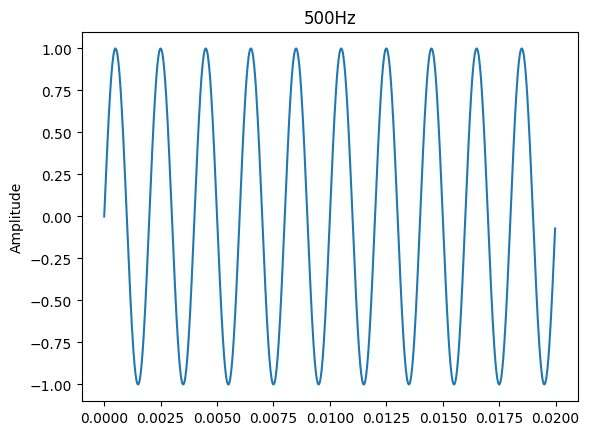

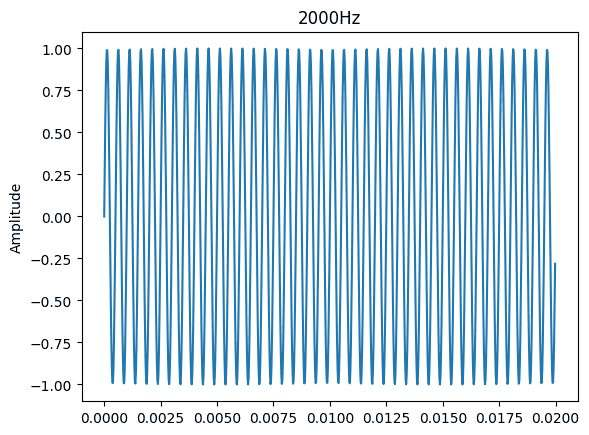

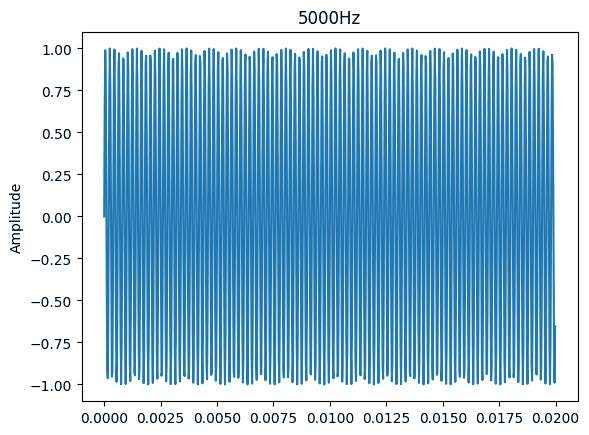

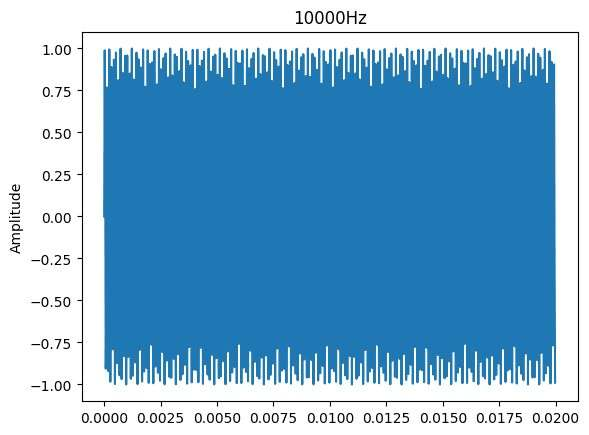

In [62]:
plot_signal(sine_waves[0], '500Hz', sampling_rate)
plot_signal(sine_waves[1], '2000Hz', sampling_rate)
plot_signal(sine_waves[2], '5000Hz', sampling_rate)
plot_signal(sine_waves[3], '10000Hz', sampling_rate)

### Step 2

In [63]:
def td_autocorr(signal):
    n= len(signal)
    r= np.zeros(n)
    for m in range(n):
        r[m] = np.sum(signal[:n-m] * signal[m:])
        r[m] /= n
    
    plt.figure(figsize=(8, 3))
    plt.plot(r)
    plt.title('Time-domain Auto-correlation')
    plt.xlabel('Time')
    plt.ylabel('Amplitude')

    return r


In [64]:
def td_autocorr_builtin(signal):
    n = len(signal)
    r = np.correlate(signal, signal, mode="full")[n - 1:] / n

    plt.figure(figsize=(8, 3))
    plt.plot(r)
    plt.title('Time-domain Auto-correlation (built-in)')
    plt.xlabel('Time')
    plt.ylabel('Amplitude')
    
    return r


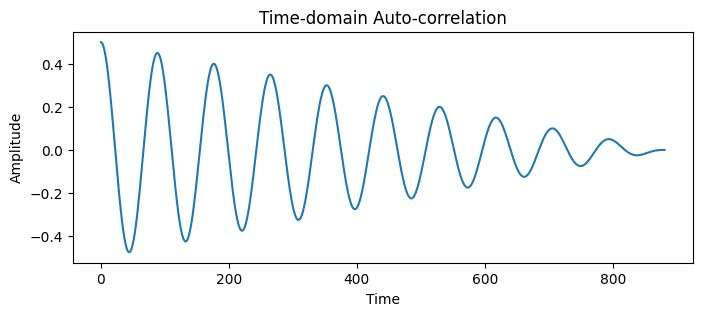

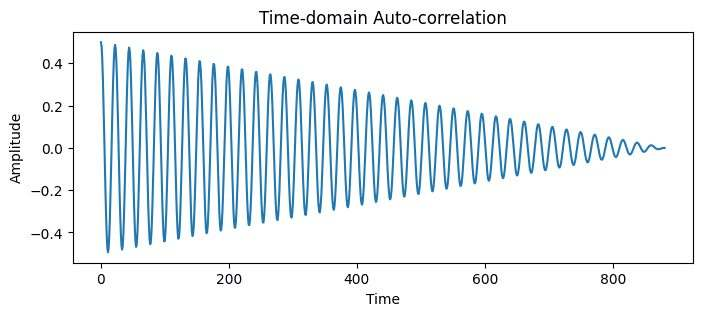

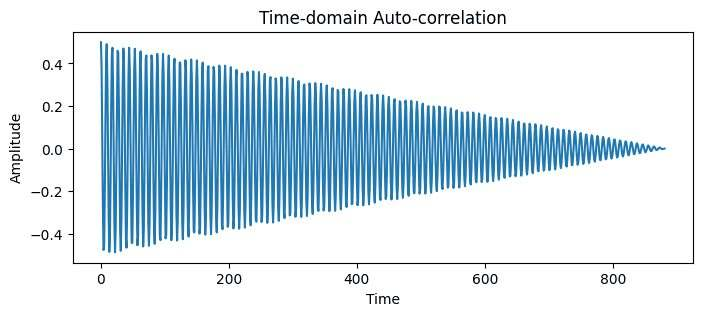

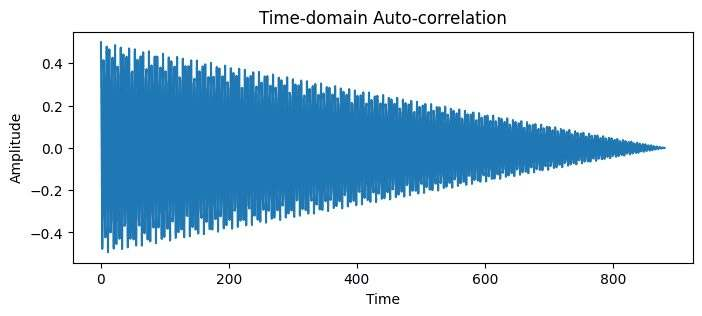

In [65]:
for wave,freq in zip(sine_waves,frequencies):
    x = td_autocorr(wave)
    

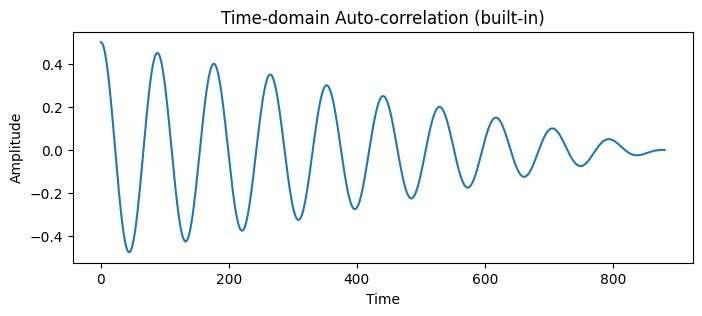

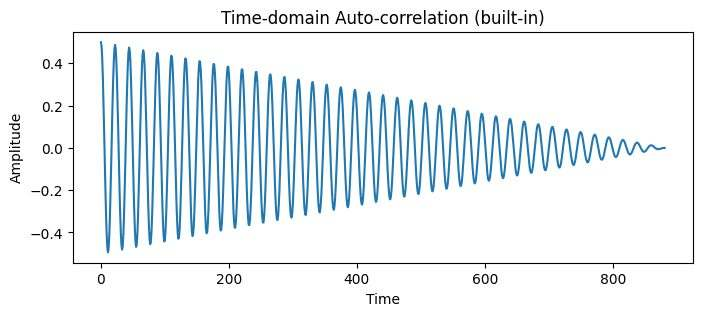

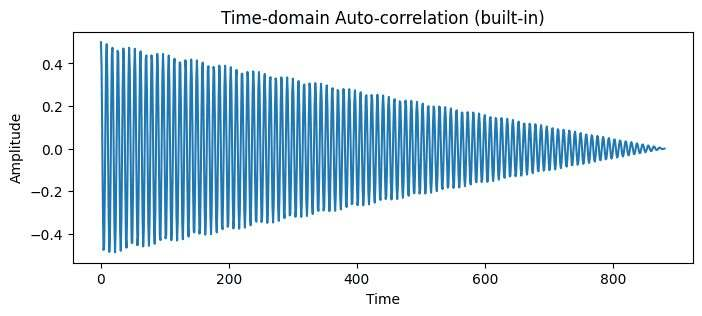

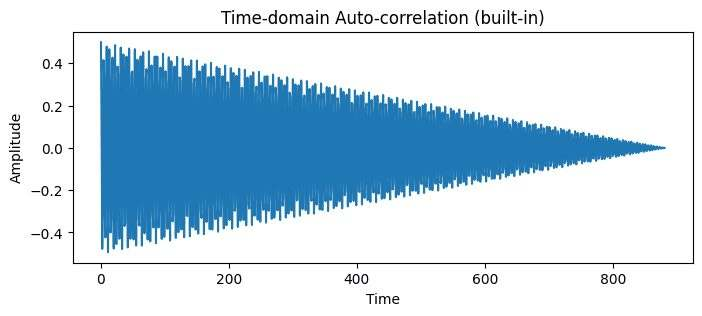

In [66]:
for wave,freq in zip(sine_waves,frequencies):
    x = td_autocorr_builtin(wave)

### Step 3

In [67]:
def dft(signal):
    n = len(signal)
    k = np.arange(n).reshape((n, 1))  # Create a column vector for k
    t = np.arange(n)  # Row vector for t
    angle = -2j * np.pi * k * t / n  # Outer product to compute all angles
    exp_matrix = np.exp(angle)  # Complex exponential for all pairs of (k, t)
    dft_result = np.matmul(exp_matrix, signal)  # Matrix multiplication
    return dft_result

In [68]:
def idft(spectrum):
    n = len(spectrum)
    k = np.arange(n).reshape((n, 1))  # Create a column vector for k
    t = np.arange(n)  # Row vector for t
    angle = 2j * np.pi * k * t / n  # Outer product to compute all angles
    exp_matrix = np.exp(angle)  # Complex exponential for all pairs of (k, t)
    signal = np.matmul(exp_matrix, spectrum) / n  # Matrix multiplication and normalization
    return signal

In [69]:
def wiener_khinchin_autocorrelation(signal):
    fft_signal = dft(signal)
    psd = np.abs(fft_signal) **2
    auto_corr = idft(psd).real

    # Plotting the results
    plt.figure(figsize=(12, 8))
    # 1. Plot the original signal
    plt.subplot(3, 1, 1)
    plt.plot(wave)
    plt.title('Original Signal')
    plt.xlabel('Time')
    plt.ylabel('Amplitude')
    # 2. Plot the magnitude of the DFT (Frequency Domain)
    plt.subplot(3, 1, 2)
    plt.plot(np.abs(fft_signal))
    plt.title('Magnitude of DFT (Frequency Domain)')
    plt.xlabel('Frequency bin')
    plt.ylabel('Magnitude')

    # 3. Plot the Power Spectral Density (PSD)
    plt.subplot(3, 1, 3)
    plt.plot(psd)
    plt.title('Power Spectral Density (PSD)')
    plt.xlabel('Frequency bin')
    plt.ylabel('Power')

    plt.tight_layout()
    plt.show()

    # Plot the Autocorrelation result
    plt.figure(figsize=(12, 3))
    plt.plot(auto_corr)
    plt.title('Autocorrelation (Inverse of PSD via IDFT)')
    plt.xlabel('Lag')
    plt.ylabel('Autocorrelation')
    plt.show()
    print('==============================================================')
    
    return fft_signal, psd, auto_corr


In [70]:
def wiener_khinchin_autocorrelation_builtin(signal):
    fft_signal = np.fft.fft(signal)
    psd = np.abs(fft_signal) **2
    auto_corr = np.fft.ifft(psd).real

    # Plotting the results
    plt.figure(figsize=(12, 8))
    # 1. Plot the original signal
    plt.subplot(3, 1, 1)
    plt.plot(wave)
    plt.title('Original Signal')
    plt.xlabel('Time')
    plt.ylabel('Amplitude')
    # 2. Plot the magnitude of the DFT (Frequency Domain)
    plt.subplot(3, 1, 2)
    plt.plot(np.abs(fft_signal))
    plt.title('Magnitude of DFT (Frequency Domain)')
    plt.xlabel('Frequency bin')
    plt.ylabel('Magnitude')

    # 3. Plot the Power Spectral Density (PSD)
    plt.subplot(3, 1, 3)
    plt.plot(psd)
    plt.title('Power Spectral Density (PSD)')
    plt.xlabel('Frequency bin')
    plt.ylabel('Power')

    plt.tight_layout()
    plt.show()

    # Plot the Autocorrelation result
    plt.figure(figsize=(12, 3))
    plt.plot(auto_corr)
    plt.title('Autocorrelation (Inverse of PSD via IDFT)')
    plt.xlabel('Lag')
    plt.ylabel('Autocorrelation')
    plt.show()
    print('==============================================================')

    return fft_signal, psd, auto_corr


Plots for signal frequency = 500Hz


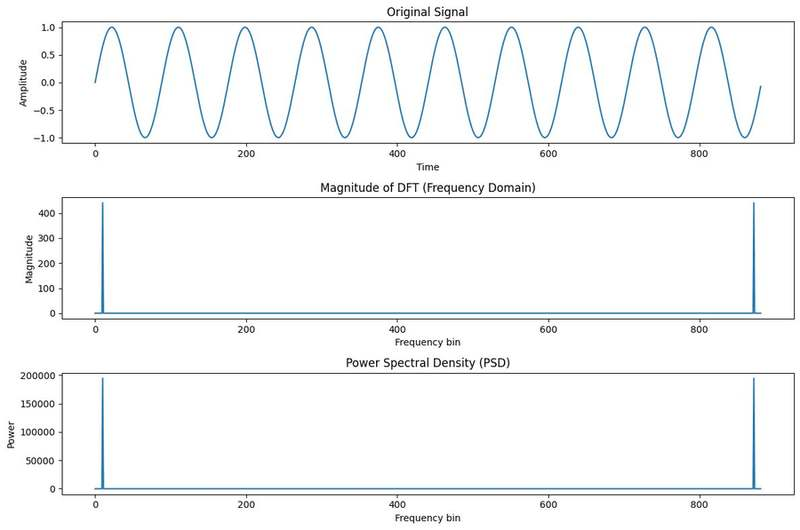

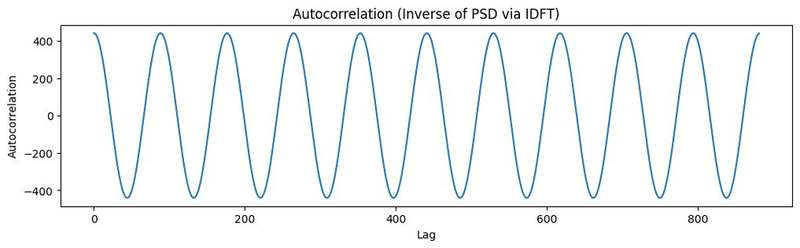

Plots for signal frequency = 2000Hz


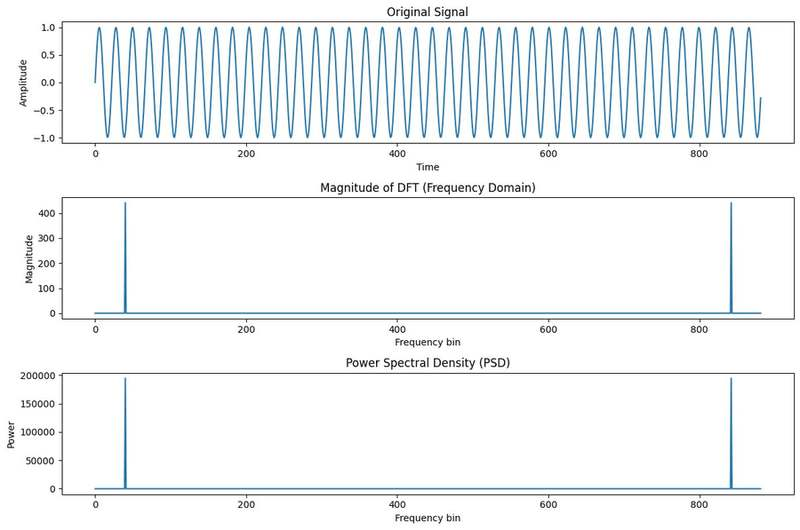

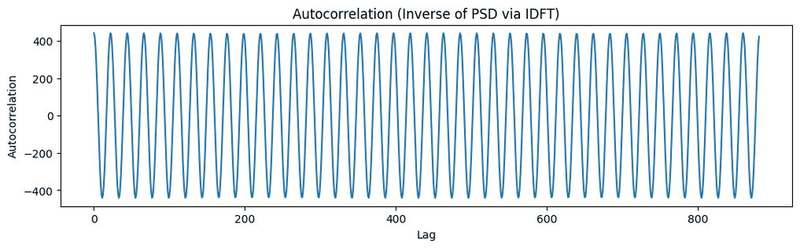

Plots for signal frequency = 5000Hz


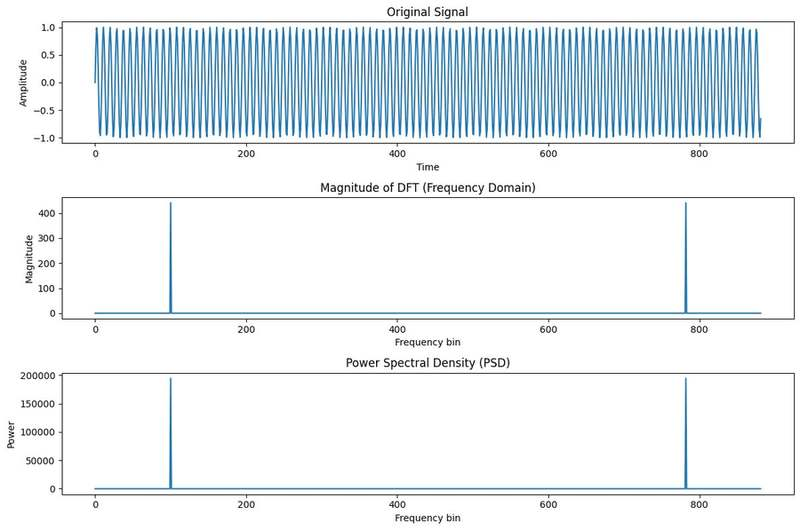

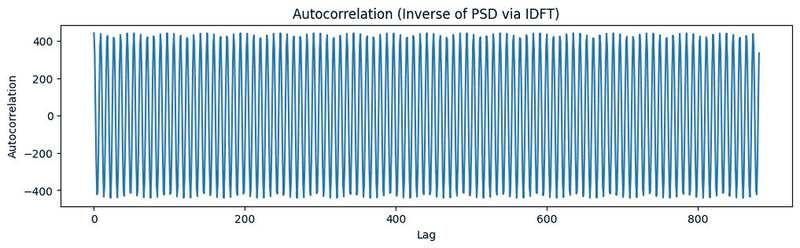

Plots for signal frequency = 10000Hz


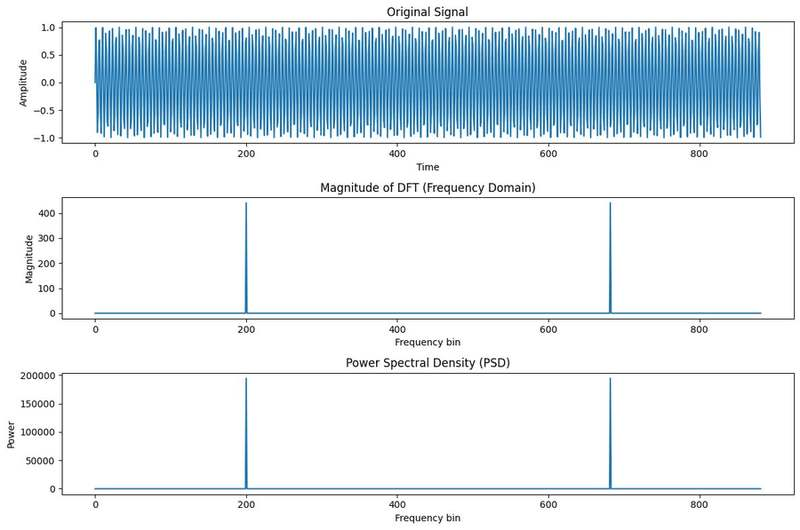

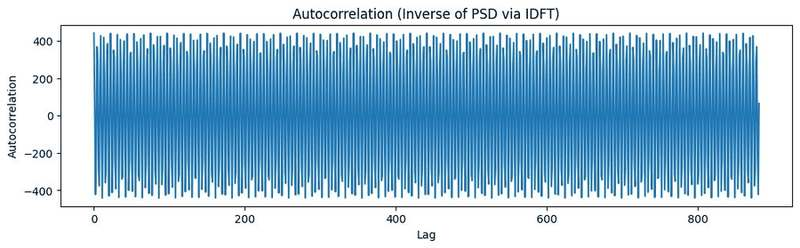

In [71]:
for freq, wave in zip(frequencies,sine_waves):
    print(f"Plots for signal frequency = {freq}Hz")
    fft_signal, psd, auto_corr = wiener_khinchin_autocorrelation(wave)

Plots for signal frequency = 500Hz (builtin)


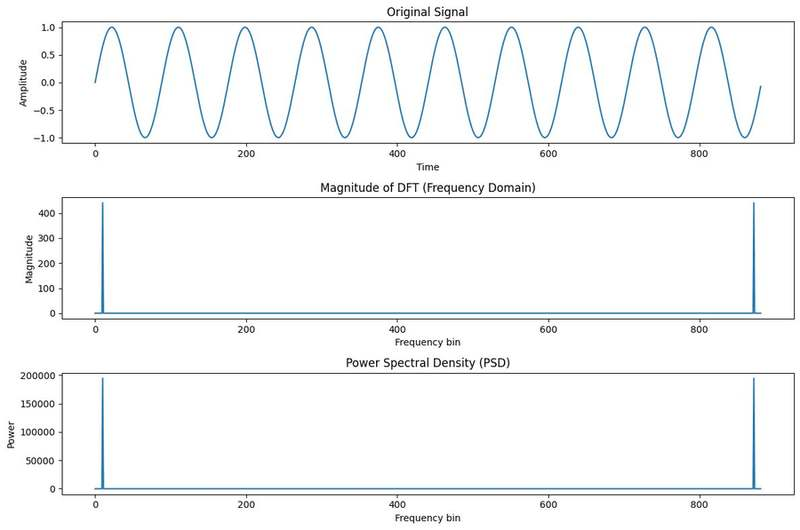

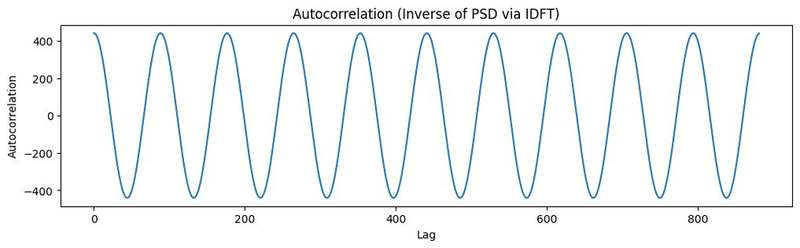

Plots for signal frequency = 2000Hz (builtin)


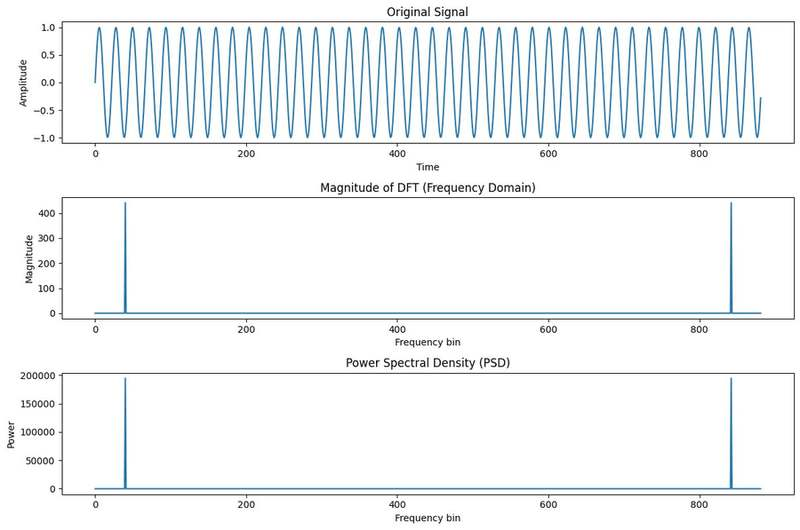

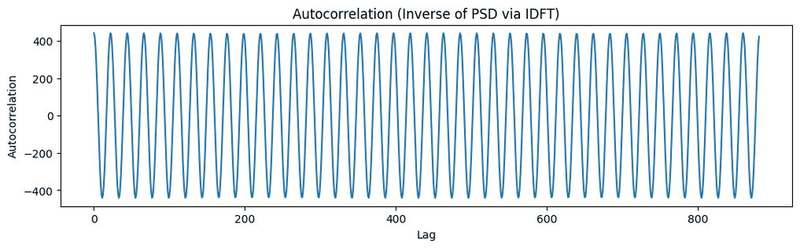

Plots for signal frequency = 5000Hz (builtin)


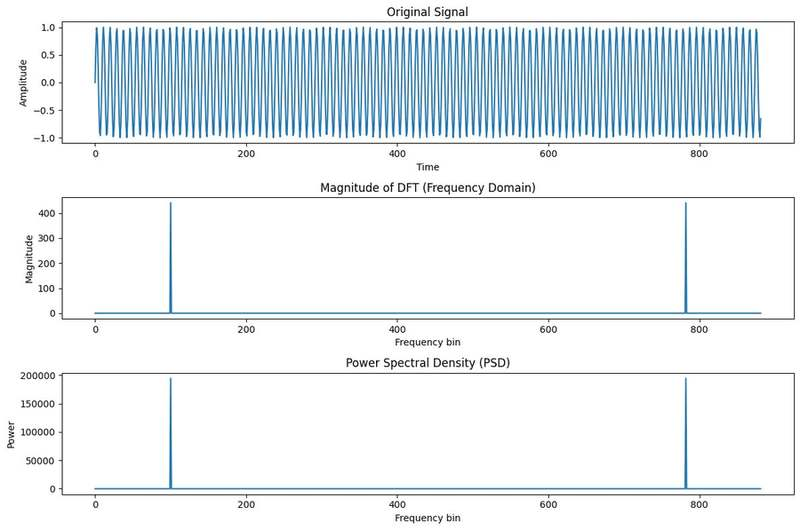

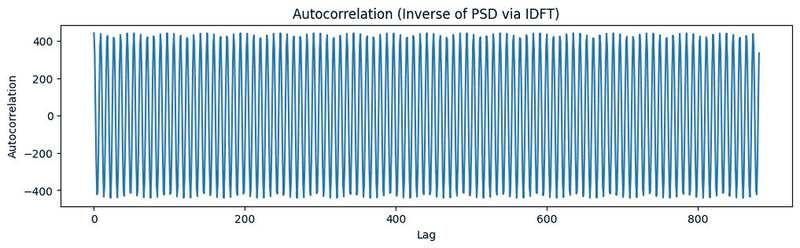

Plots for signal frequency = 10000Hz (builtin)


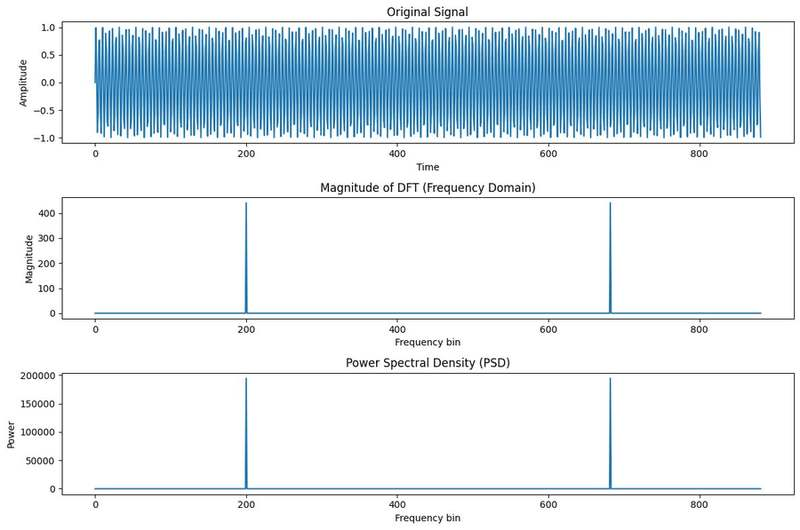

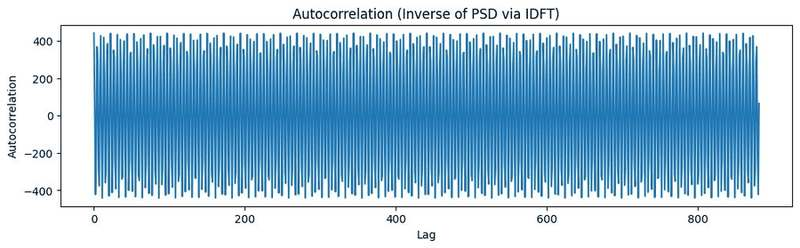

In [72]:
for freq, wave in zip(frequencies,sine_waves):
    print(f"Plots for signal frequency = {freq}Hz (builtin)")
    fft_signal, psd, auto_corr = wiener_khinchin_autocorrelation_builtin(wave)

### Step 4

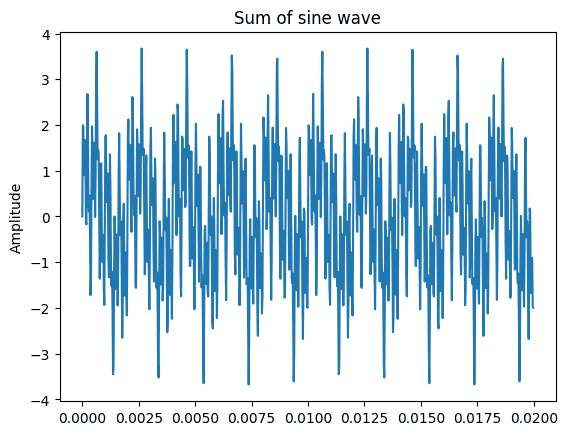

In [73]:
sum_waves= sum(sine_waves)
plot_signal(sum_waves,'Sum of sine wave', sampling_rate)

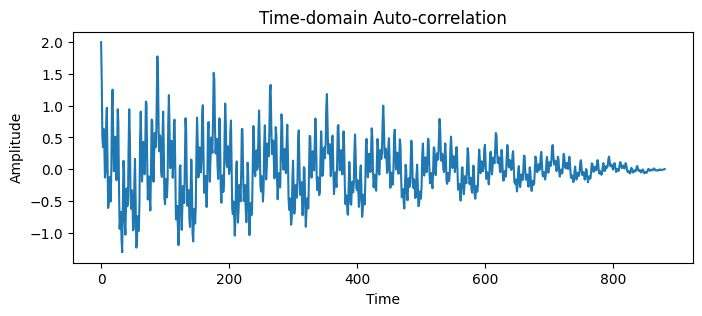

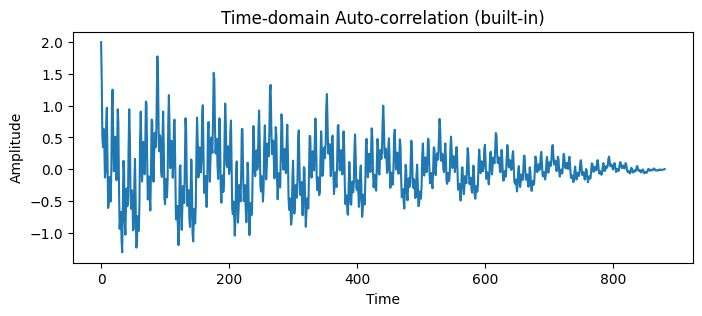

In [74]:
x= td_autocorr(sum_waves)
x= td_autocorr_builtin(sum_waves)

Plots for signal with sum of 4 frequencies


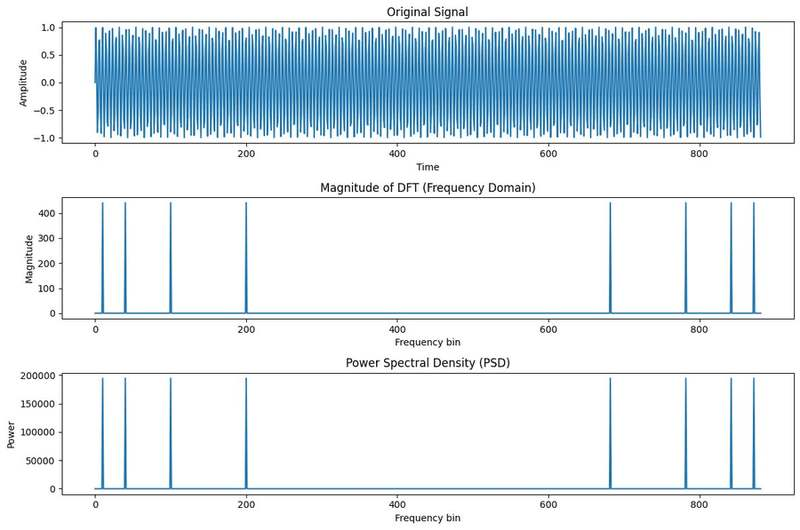

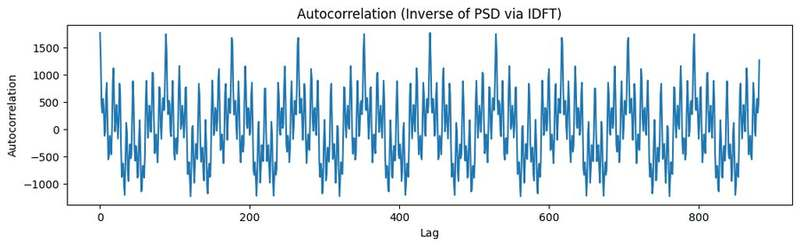

Plots for signal with sum of 4 frequencies (built-in)


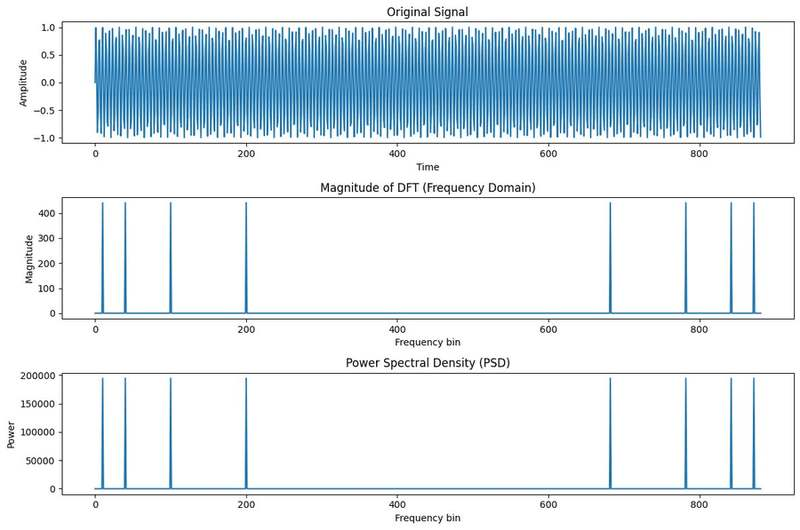

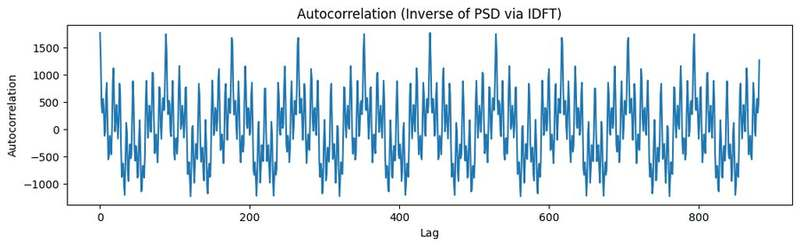

In [75]:
print("Plots for signal with sum of 4 frequencies")
fft_signal, psd, auto_corr = wiener_khinchin_autocorrelation(sum_waves)

print("Plots for signal with sum of 4 frequencies (built-in)")
fft_signal, psd, auto_corr = wiener_khinchin_autocorrelation_builtin(sum_waves)

### Step 5

In [76]:
noisy_sine_waves = [wave + np.random.normal(0, 0.2, len(wave)) for wave in sine_waves]

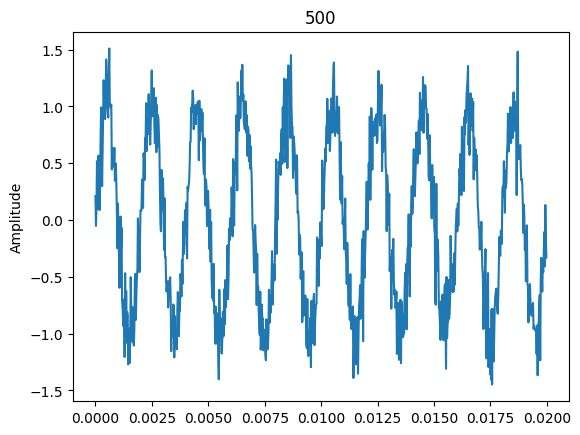

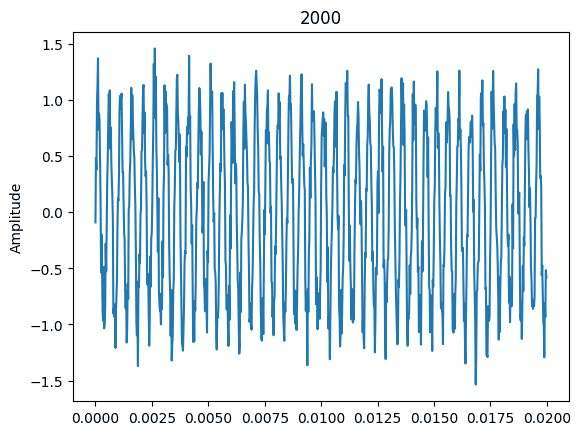

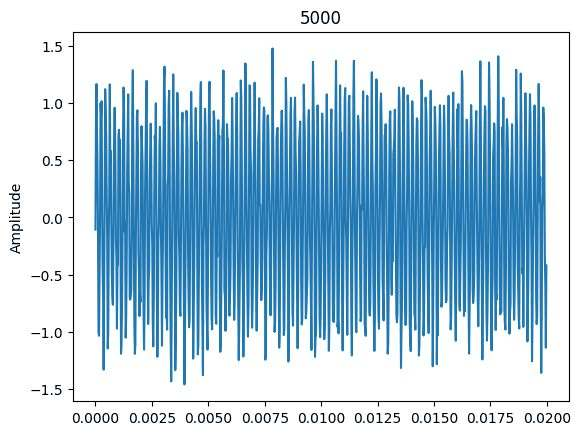

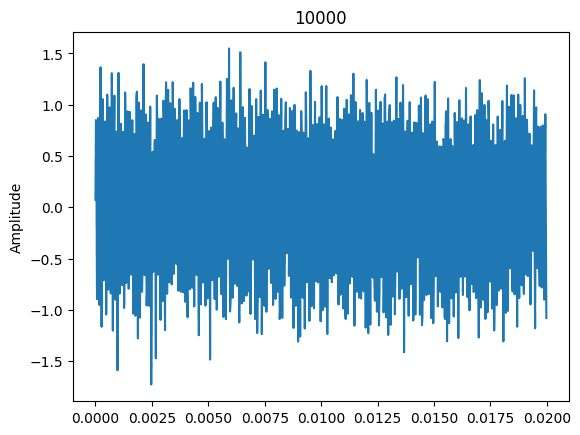

In [77]:
for wave,freq in zip(noisy_sine_waves,frequencies):
    plot_signal(wave, freq, sampling_rate)

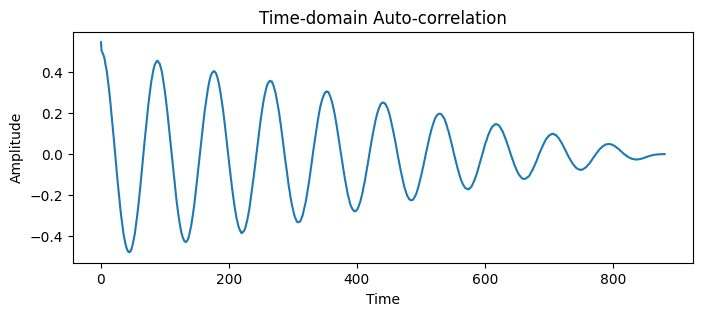

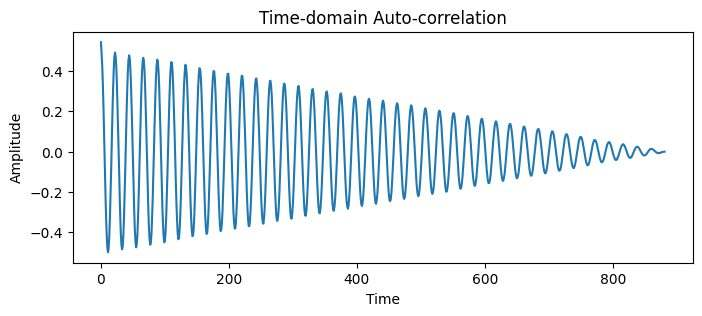

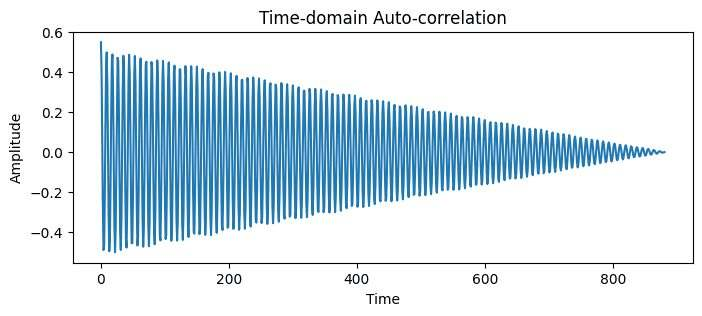

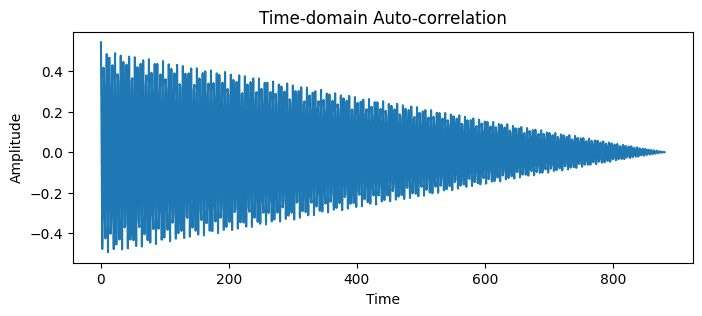

In [78]:
for wave,freq in zip(noisy_sine_waves,frequencies):
    x = td_autocorr(wave)

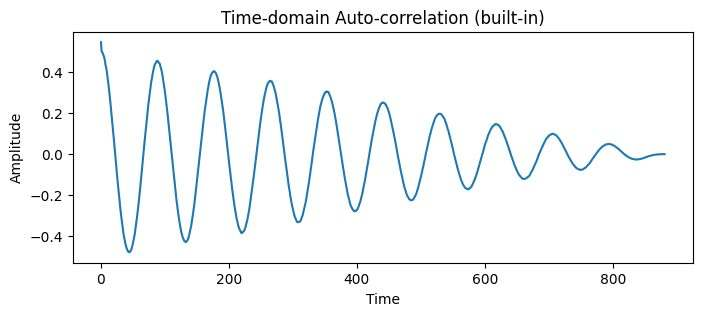

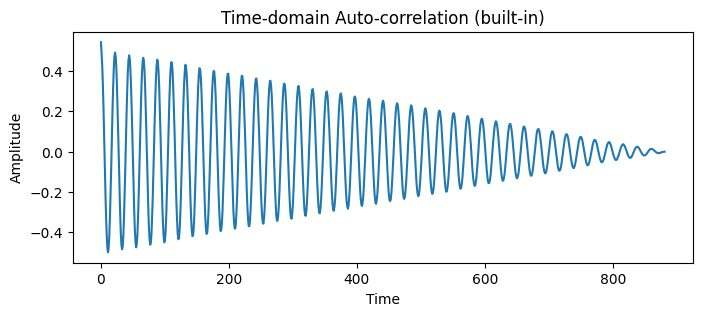

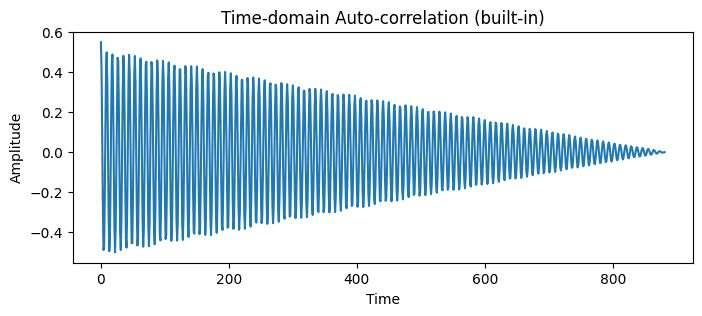

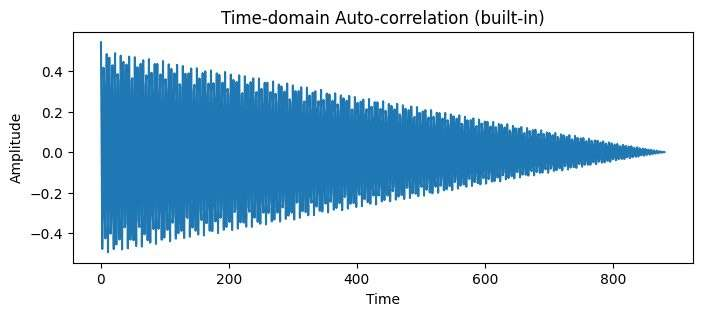

In [79]:
for wave,freq in zip(noisy_sine_waves,frequencies):
    x = td_autocorr_builtin(wave)

Plots for signal frequency = 500Hz


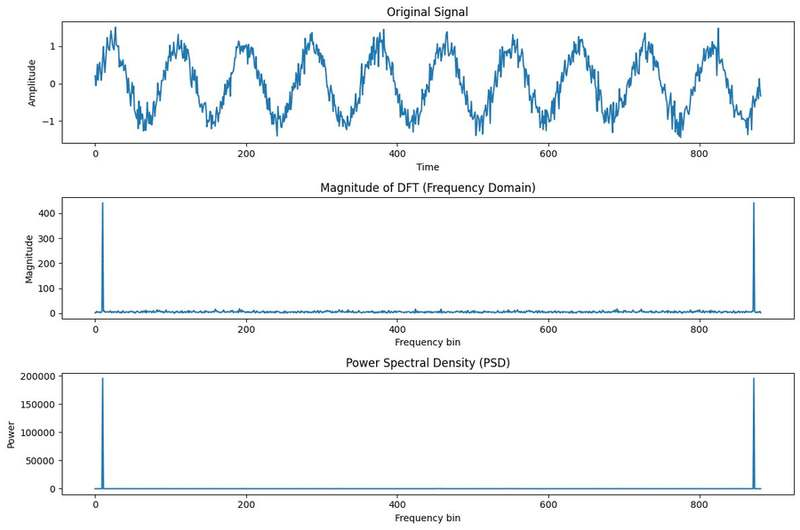

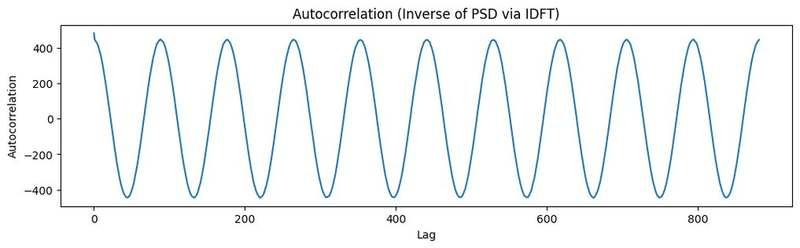

Plots for signal frequency = 2000Hz


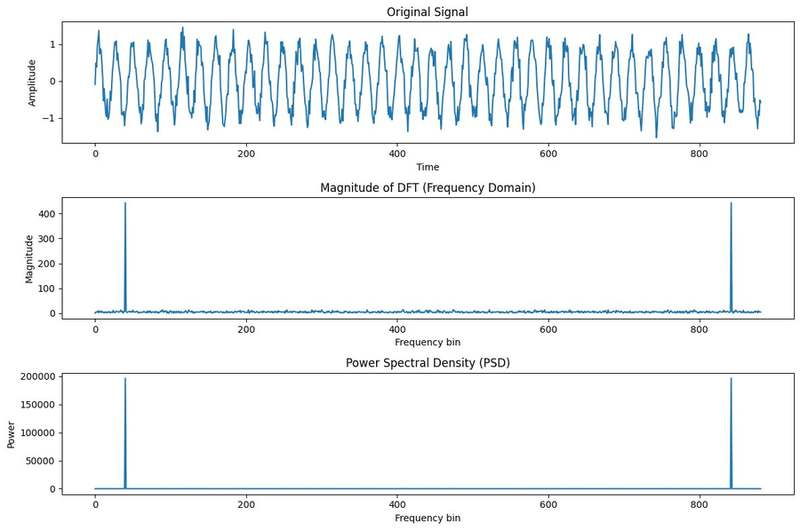

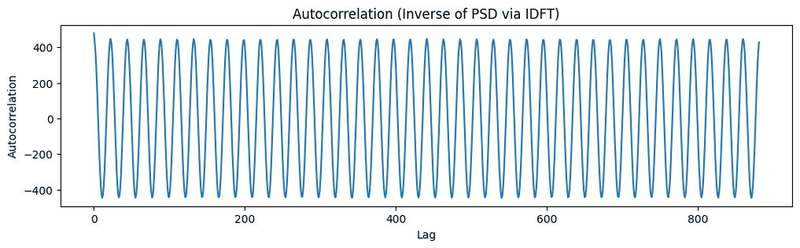

Plots for signal frequency = 5000Hz


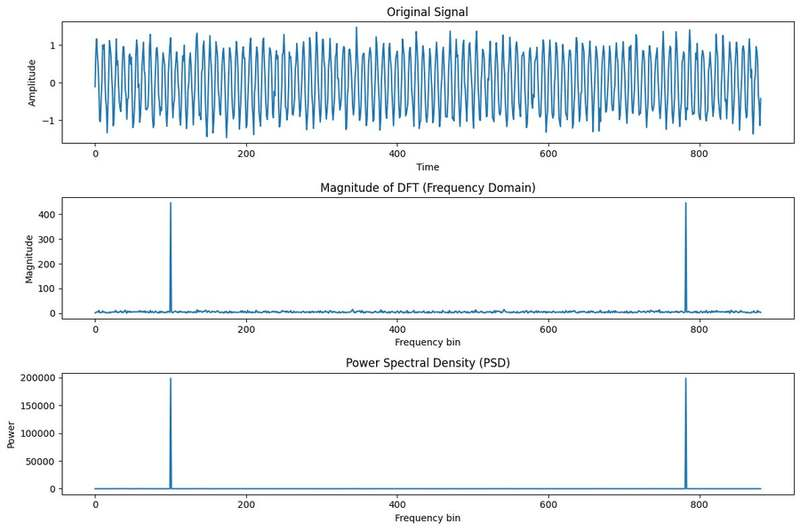

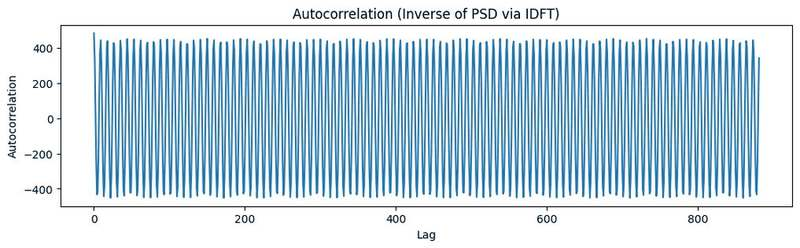

Plots for signal frequency = 10000Hz


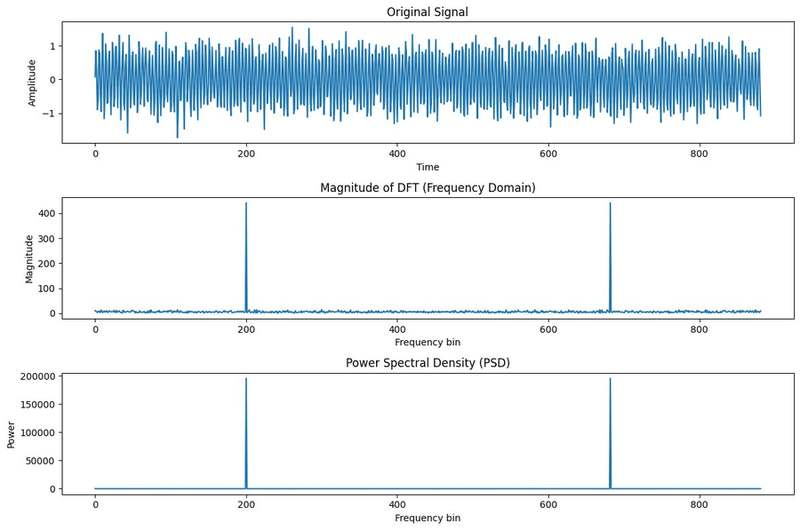

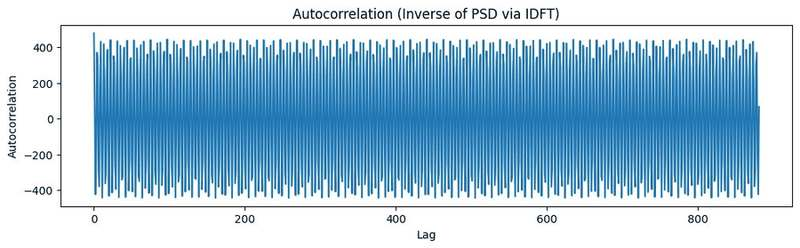

In [80]:
for freq, wave in zip(frequencies,noisy_sine_waves):
    print(f"Plots for signal frequency = {freq}Hz")
    fft_signal, psd, auto_corr = wiener_khinchin_autocorrelation(wave)


Plots for signal frequency = 500Hz (Built-in)


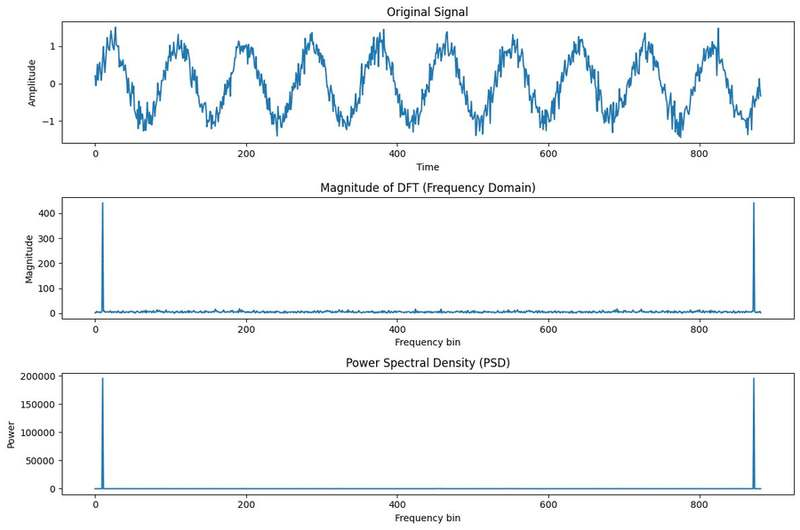

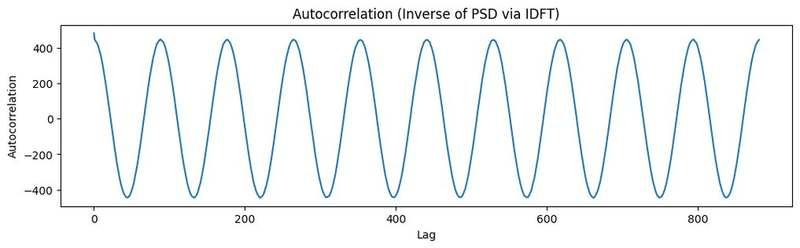

Plots for signal frequency = 2000Hz (Built-in)


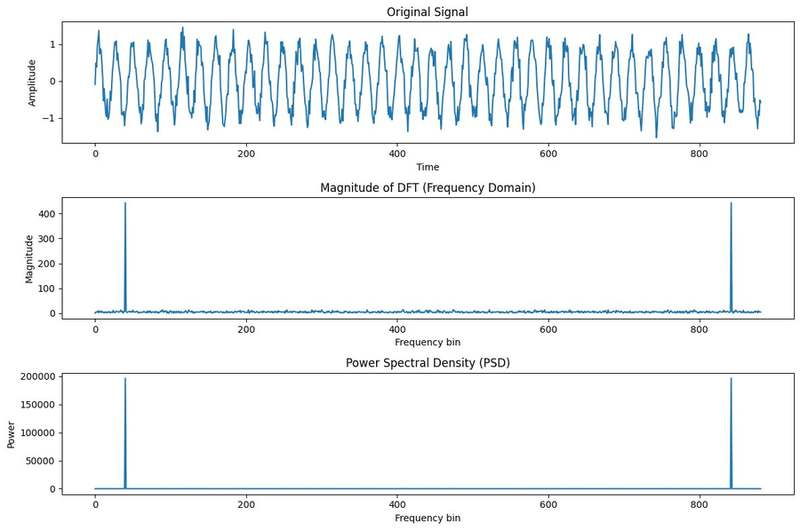

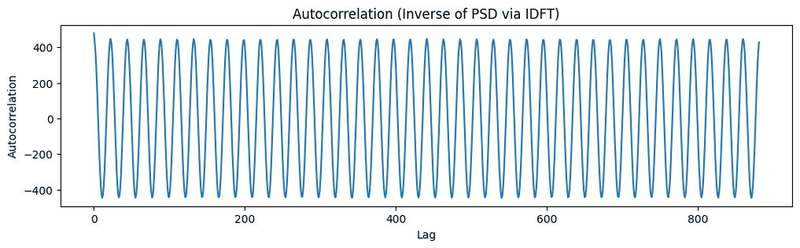

Plots for signal frequency = 5000Hz (Built-in)


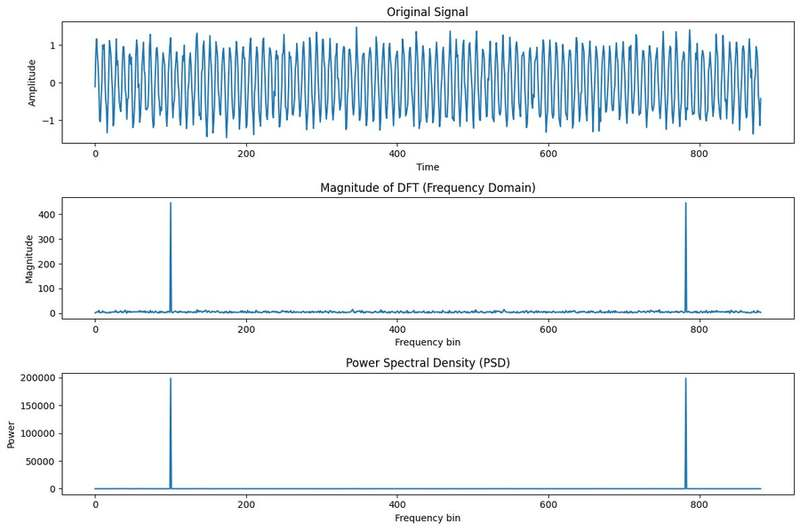

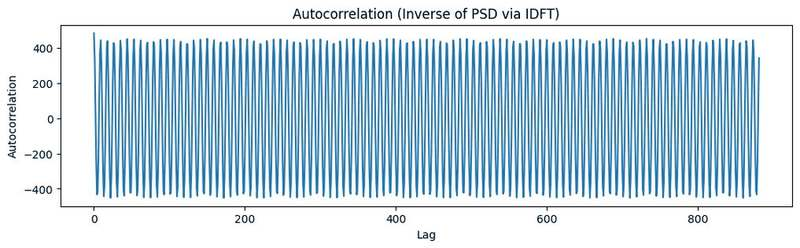

Plots for signal frequency = 10000Hz (Built-in)


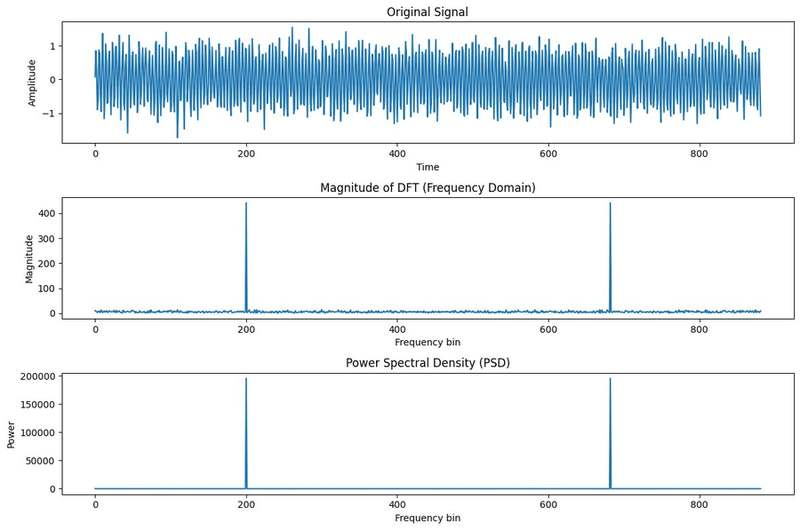

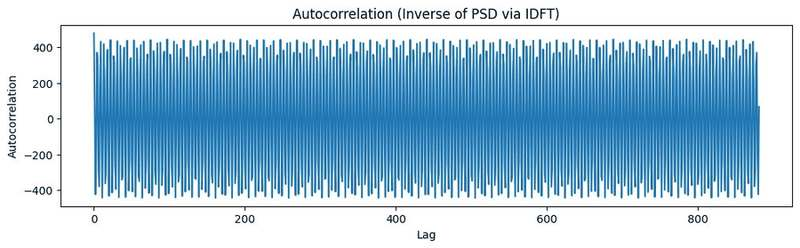

In [81]:
for freq, wave in zip(frequencies,noisy_sine_waves):
    print(f"Plots for signal frequency = {freq}Hz (Built-in)")
    fft_signal, psd, auto_corr = wiener_khinchin_autocorrelation_builtin(wave)

### Step 6

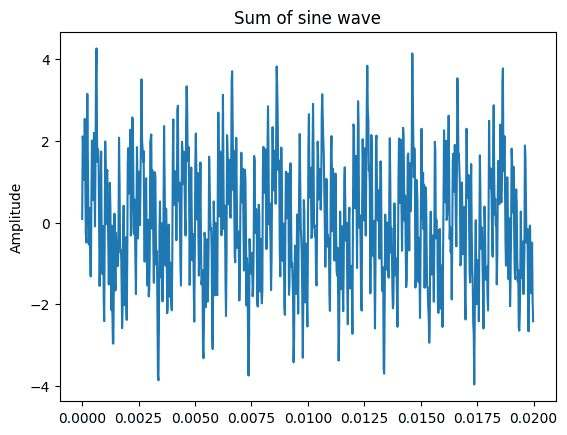

In [82]:
sum_waves= sum(noisy_sine_waves)
plot_signal(sum_waves,'Sum of sine wave', sampling_rate)


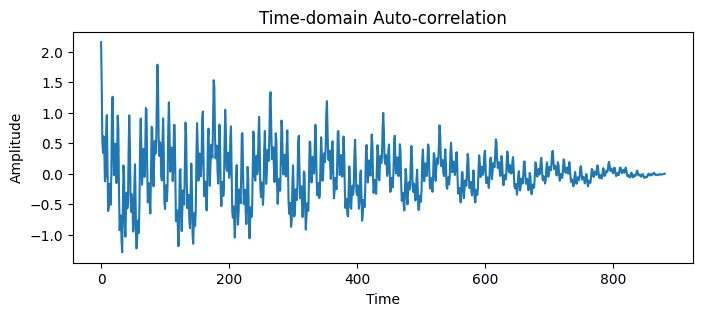

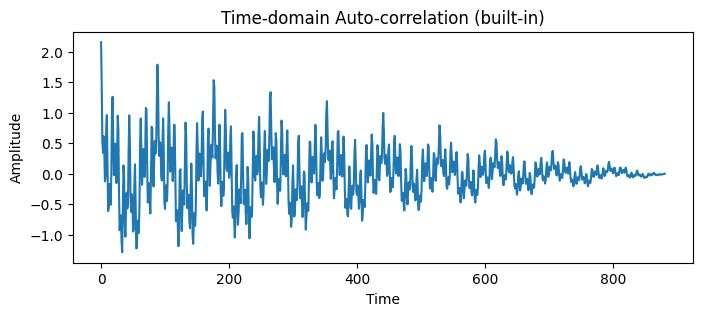

In [83]:
x= td_autocorr(sum_waves)
x= td_autocorr_builtin(sum_waves)

Plots for signal with sum of 4 frequencies


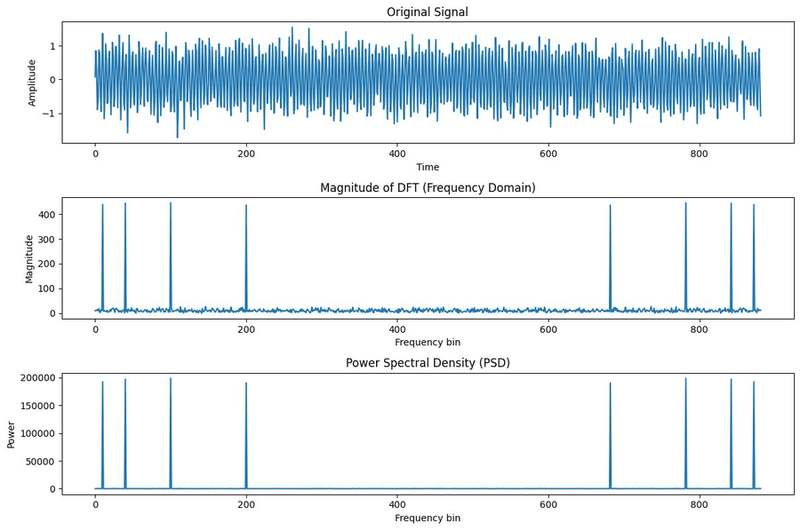

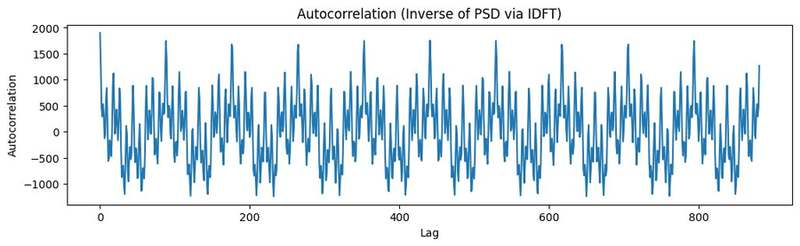

Plots for signal with sum of 4 frequencies (built-in)


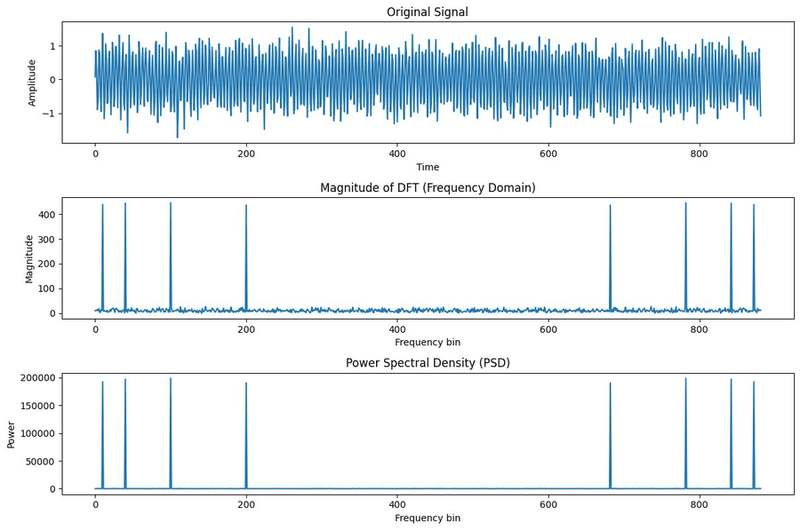

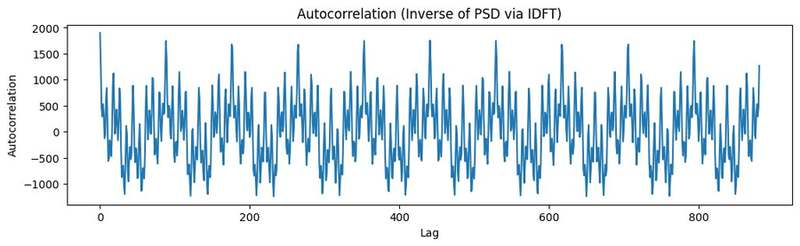

In [84]:
print("Plots for signal with sum of 4 frequencies")
fft_signal, psd, auto_corr = wiener_khinchin_autocorrelation(sum_waves)

print("Plots for signal with sum of 4 frequencies (built-in)")
fft_signal, psd, auto_corr = wiener_khinchin_autocorrelation_builtin(sum_waves)

### Step 7

In [85]:
vowel1_path= "audio/vowels/ɑɪ.wav"
vowel2_path= "audio/vowels/i.wav"
vowel3_path= "audio/vowels/u.wav"


In [86]:
vowel1_time,vowel1_sampling= lb.load(vowel1_path)
vowel2_time,vowel2_sampling= lb.load(vowel2_path)
vowel3_time,vowel3_sampling= lb.load(vowel3_path)

In [87]:
Audio(vowel1_time, rate=vowel1_sampling)


In [88]:
Audio(vowel2_time, rate=vowel2_sampling)

In [89]:
Audio(vowel3_time, rate=vowel3_sampling)

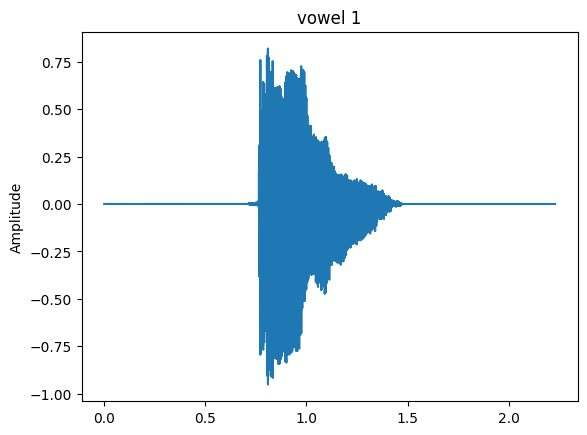

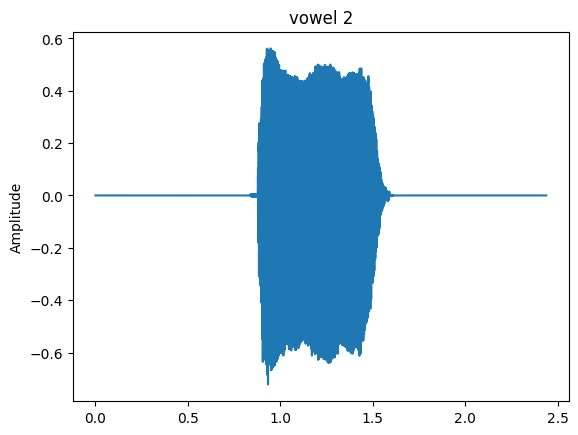

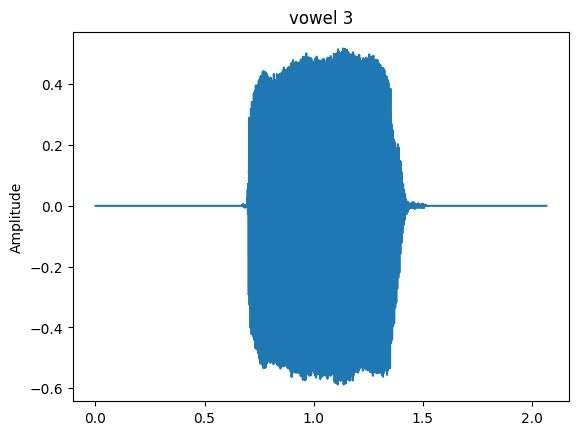

In [90]:
vowels= [vowel1_time, vowel2_time, vowel3_time]
vsr= [vowel1_sampling, vowel2_sampling, vowel3_sampling]
for sr, v,idx in zip(vsr, vowels, [i for i in range(1,len(vowels)+1)]):
    plot_signal(v, f'vowel {idx}',sr)

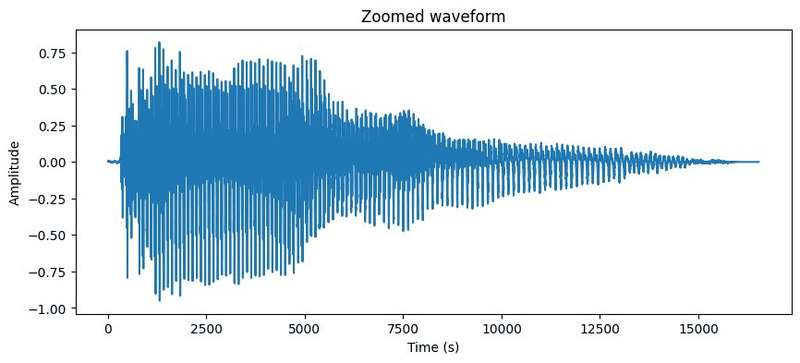

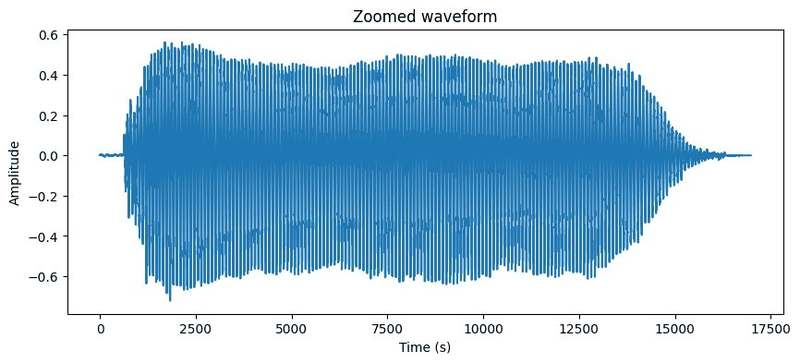

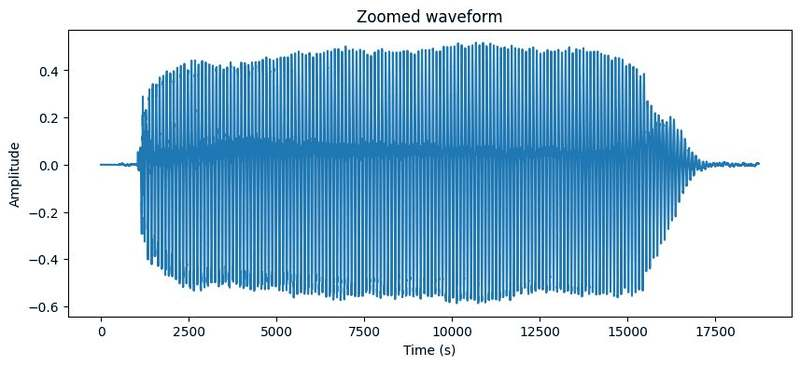

In [91]:
v1_segment= zoom_waveform(0.75, 1.5, vowel1_time, vowel1_sampling)
v2_segment= zoom_waveform(0.85, 1.62, vowel2_time, vowel2_sampling)
v3_segment= zoom_waveform(0.65, 1.5, vowel3_time, vowel3_sampling)
vowels= [v1_segment, v2_segment, v3_segment]

#### Note that vowel 1 is dipthong

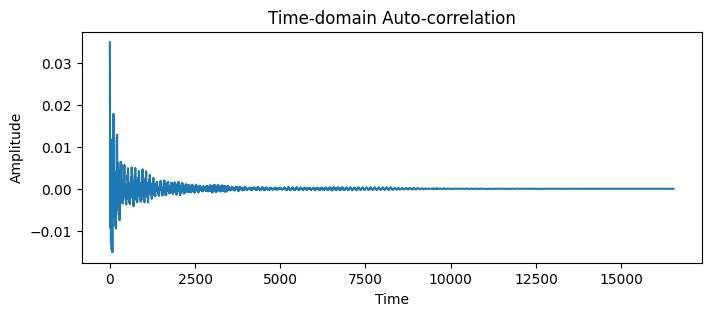

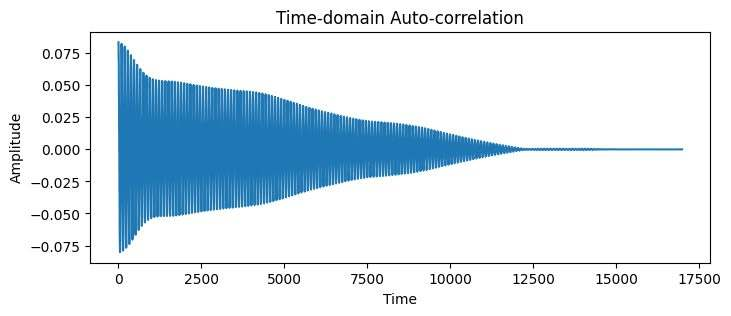

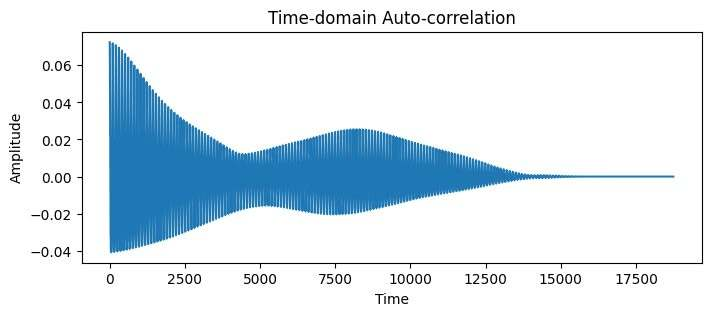

In [92]:
for v, idx in zip(vowels, [i for i in range(1,len(vowels)+1)]):
    x = td_autocorr(v)

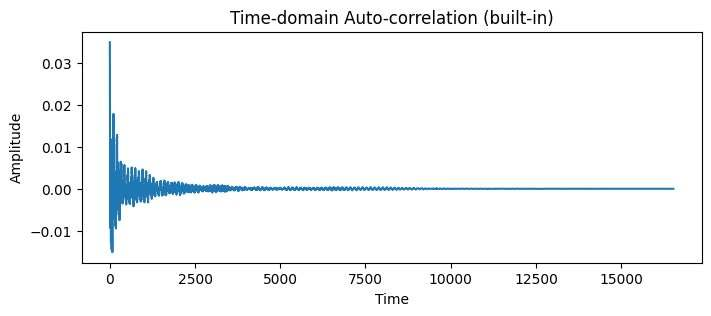

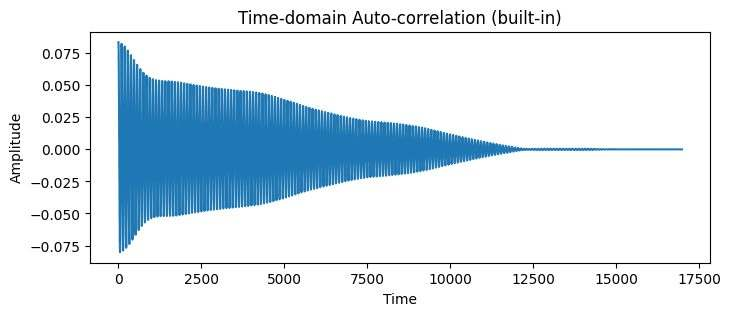

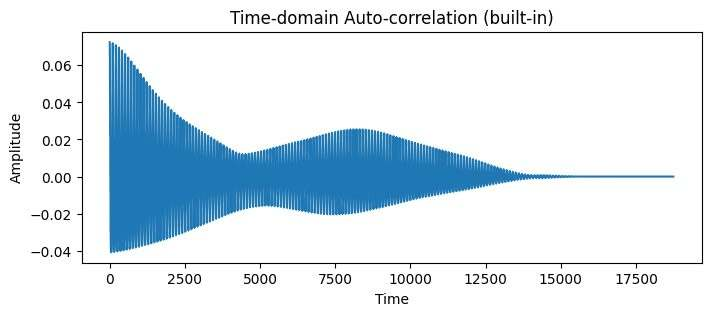

In [93]:
for v, idx in zip(vowels, [i for i in range(1,len(vowels)+1)]):
    x = td_autocorr_builtin(v)

Plots for vowel 1


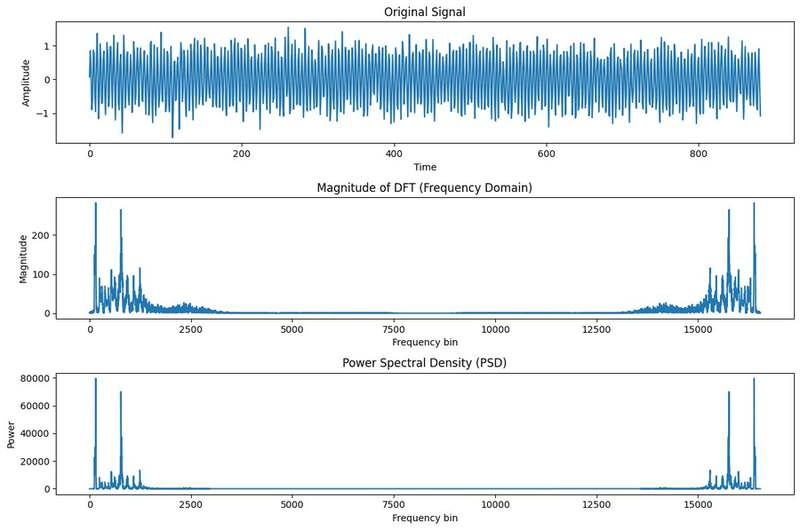

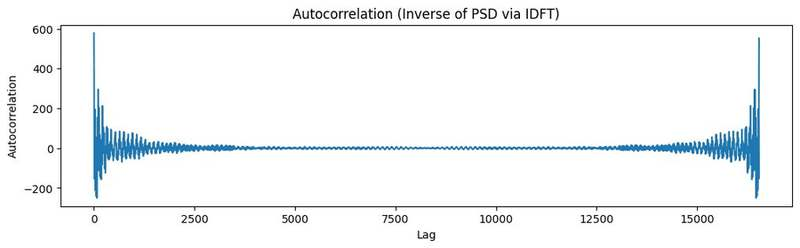

Plots for vowel 2


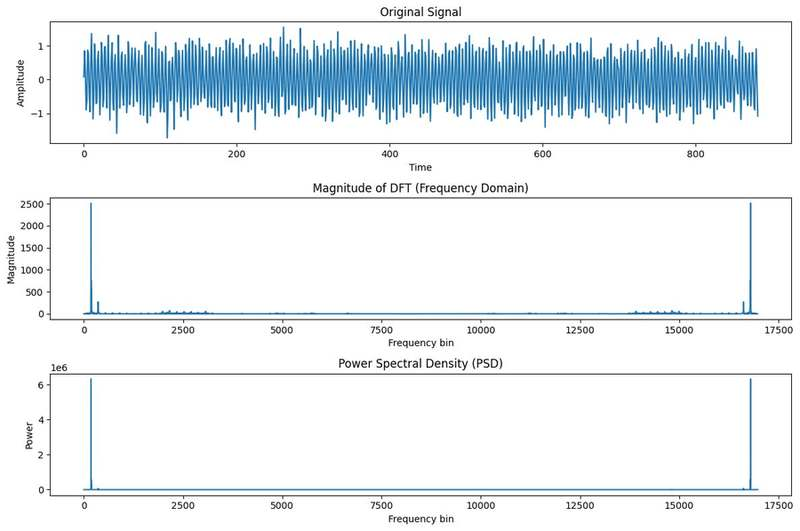

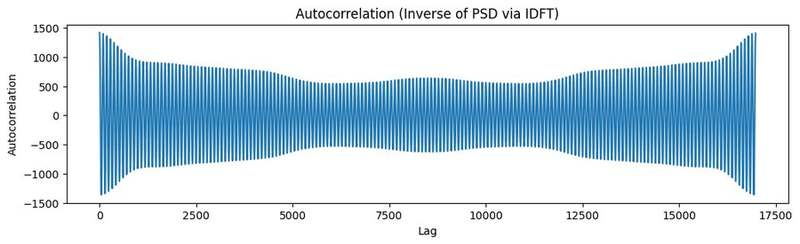

Plots for vowel 3


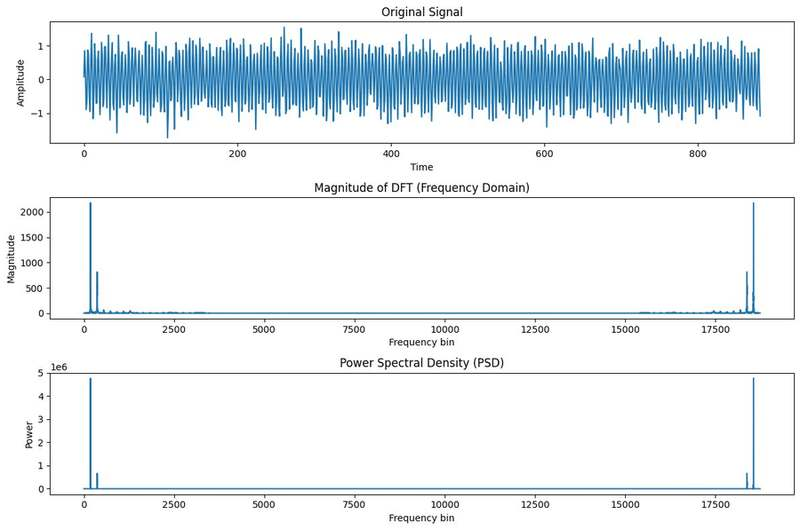

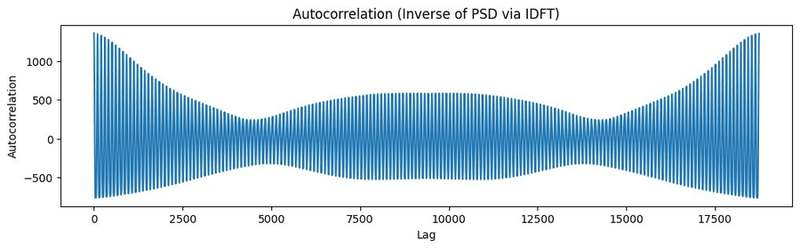

In [94]:
for v, idx in zip(vowels, [i for i in range(1,len(vowels)+1)]):
    print(f"Plots for vowel {idx}")
    fft_signal, psd, auto_corr = wiener_khinchin_autocorrelation(v)

Plots for vowel 1 (built-in)


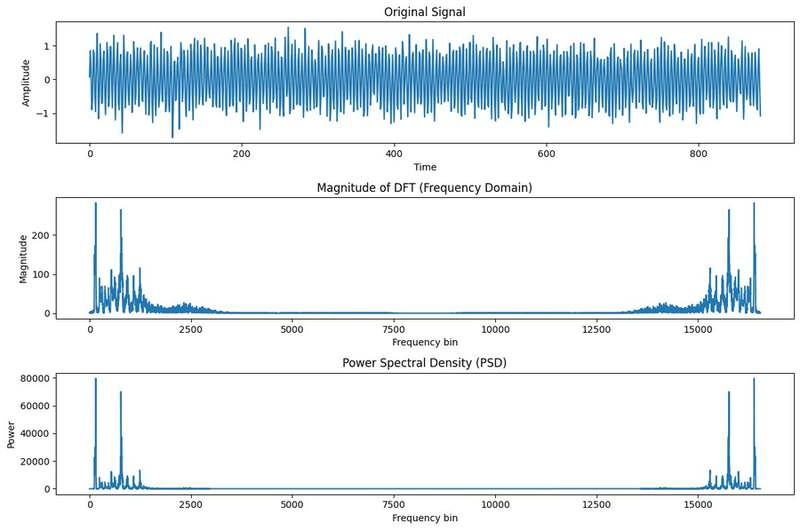

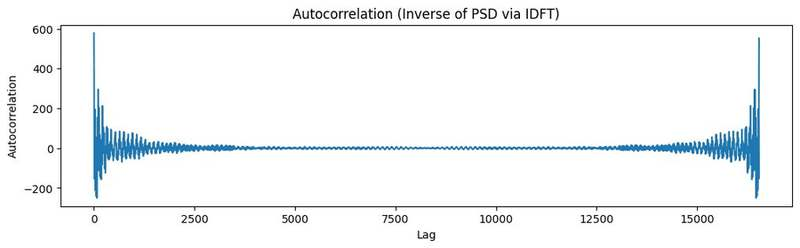

Plots for vowel 2 (built-in)


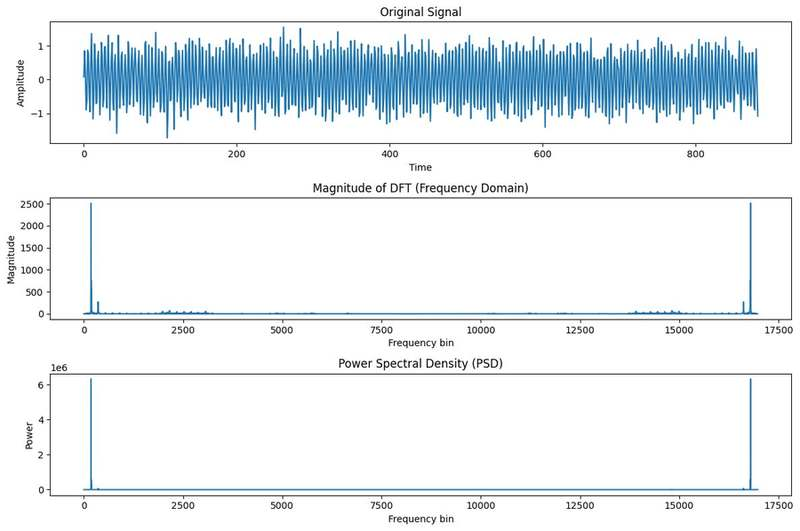

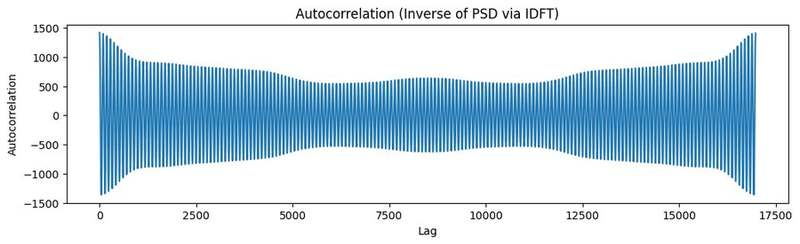

Plots for vowel 3 (built-in)


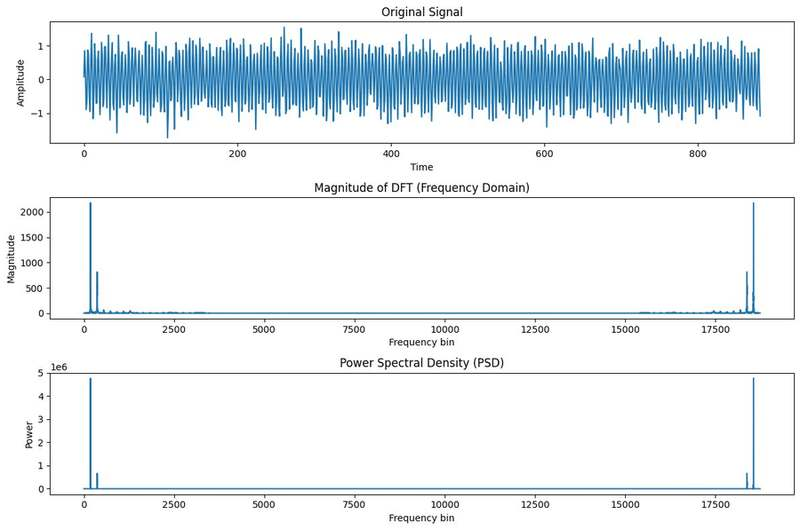

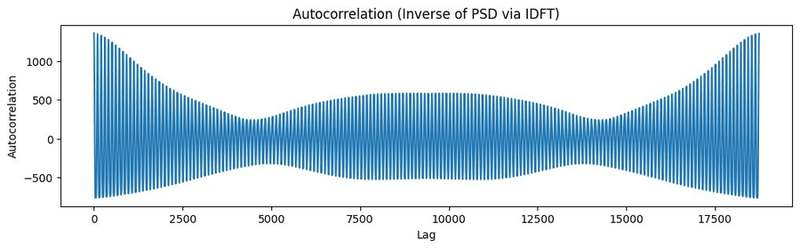

In [95]:
for v, idx in zip(vowels, [i for i in range(1,len(vowels)+1)]):
    print(f"Plots for vowel {idx} (built-in)")
    fft_signal, psd, auto_corr = wiener_khinchin_autocorrelation_builtin(v)

### Step 8

In [96]:
c1_path= "audio/consonants/ada.wav"
c2_path= "audio/consonants/aga.wav"
c3_path= "audio/consonants/ava.wav"

In [97]:
c1_time,c1_sampling= lb.load(c1_path)
c2_time,c2_sampling= lb.load(c2_path)
c3_time,c3_sampling= lb.load(c3_path)

In [98]:
Audio(c1_time, rate=c1_sampling)

In [99]:
Audio(c2_time, rate=c2_sampling)


In [100]:
Audio(c3_time, rate=c3_sampling)


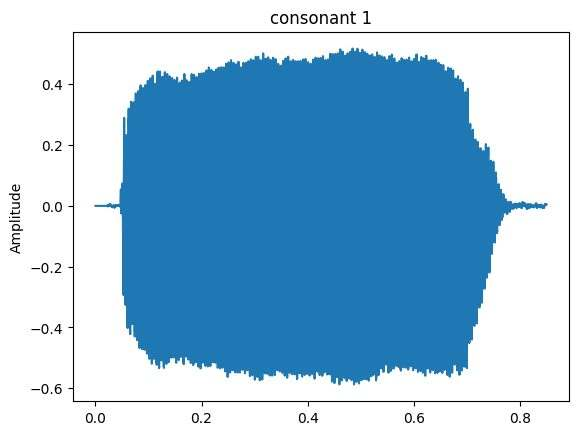

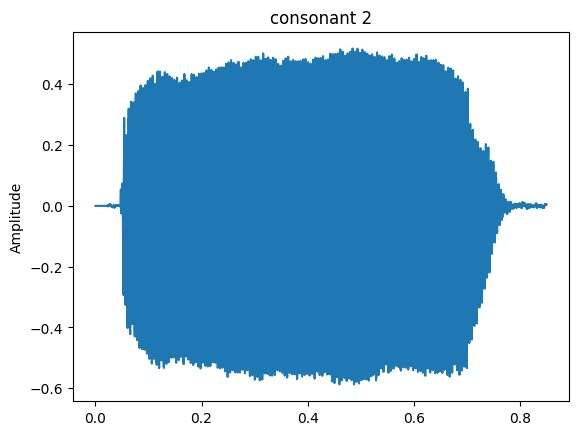

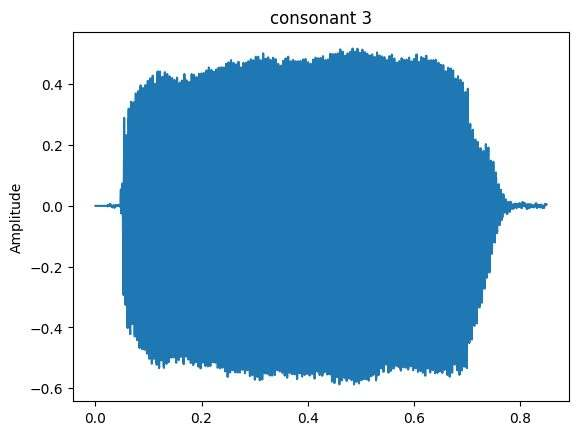

In [101]:
consonants= [c1_time, c2_time, c3_time]
csr= [c1_sampling, c2_sampling, c3_sampling]
for sr, c,idx in zip(csr, consonants, [i for i in range(1,len(consonants)+1)]):
    plot_signal(v, f'consonant {idx}',sr)

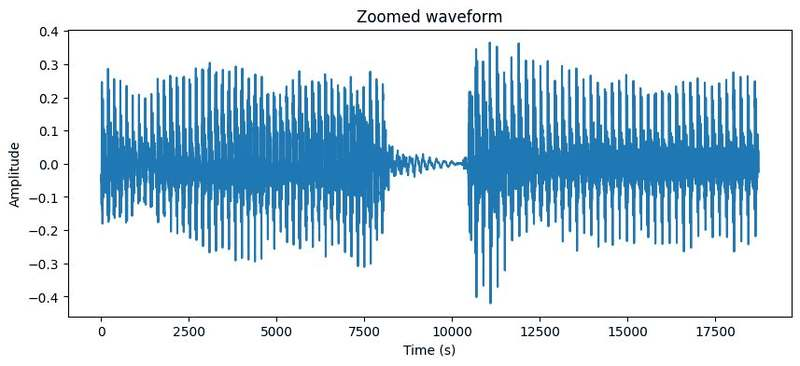

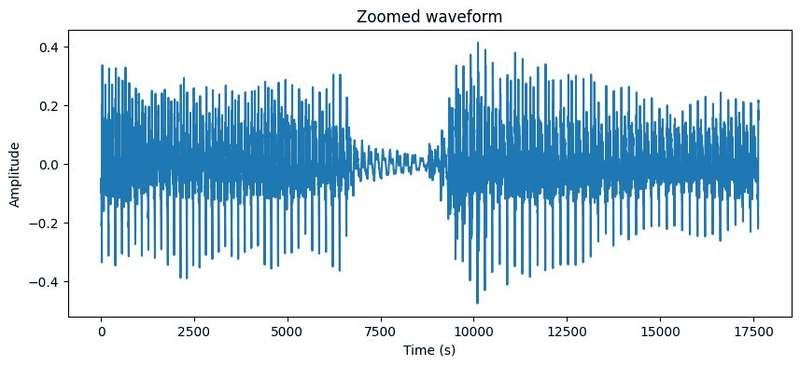

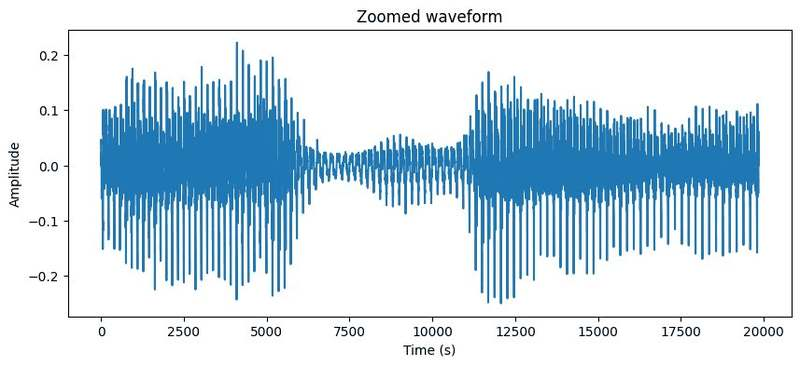

In [102]:
c1_segment= zoom_waveform(0.4, 1.25, c1_time, c1_sampling)
c2_segment= zoom_waveform(1, 1.8, c2_time, c2_sampling)
c3_segment= zoom_waveform(0.6, 1.5, c3_time, c3_sampling)
consonants=[c1_segment,c2_segment,c3_segment]

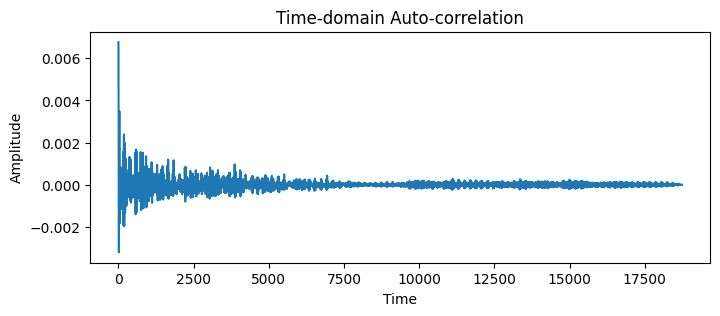

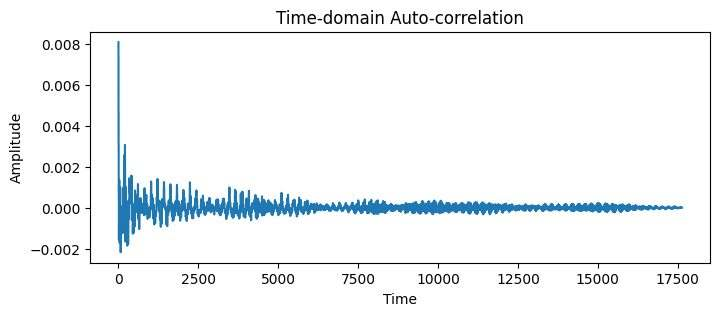

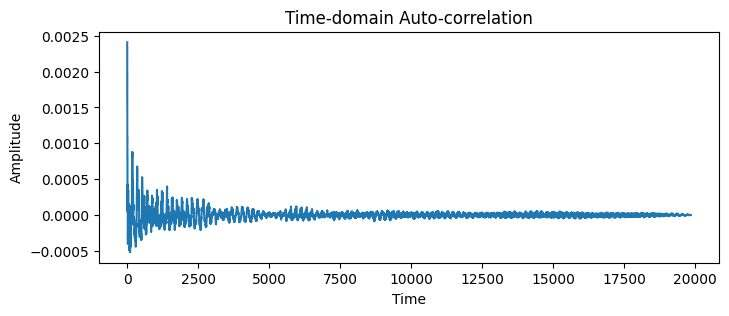

In [103]:
for c, idx in zip(consonants, [i for i in range(1,len(consonants)+1)]):
    x = td_autocorr(c)

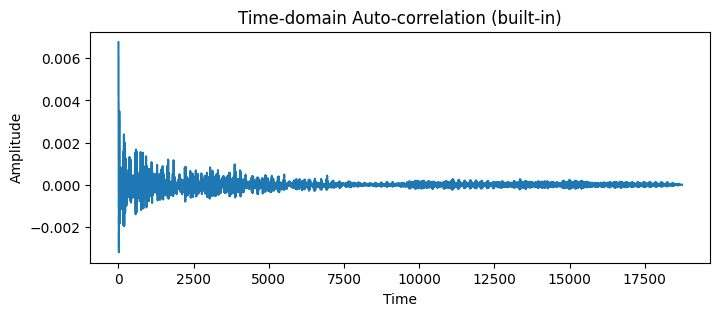

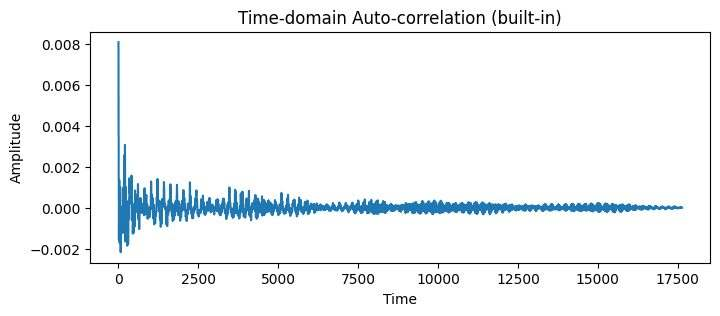

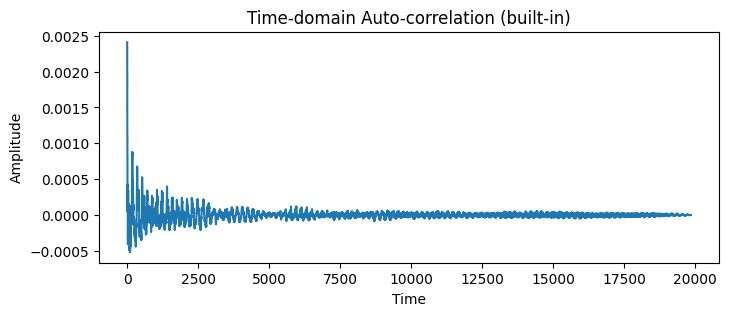

In [104]:
for c, idx in zip(consonants, [i for i in range(1,len(consonants)+1)]):
    x = td_autocorr_builtin(c)

Plots for consonant 1


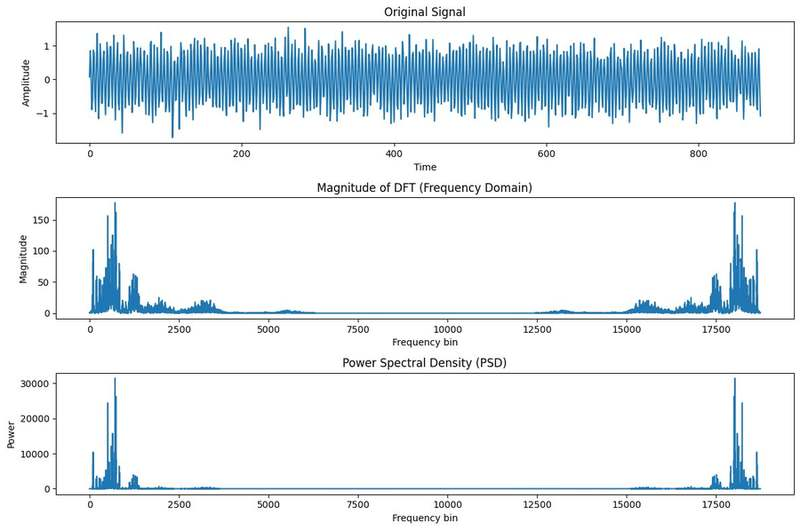

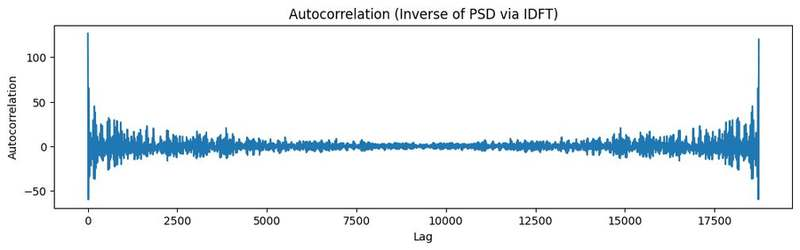

Plots for consonant 2


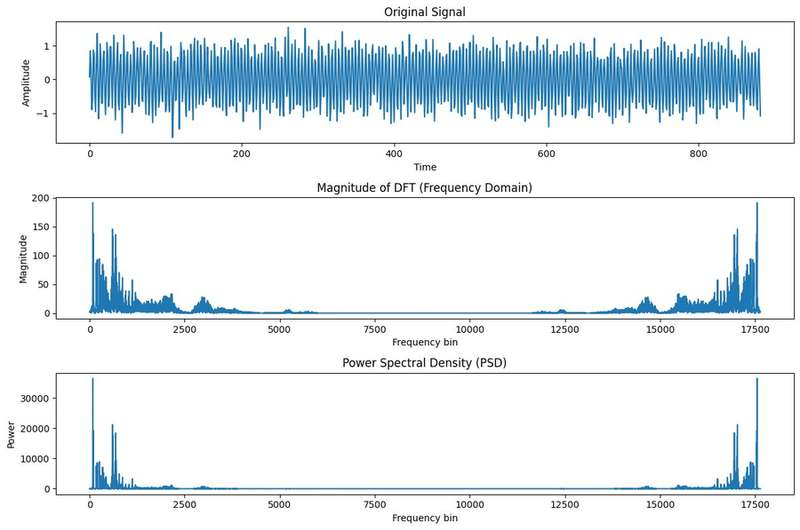

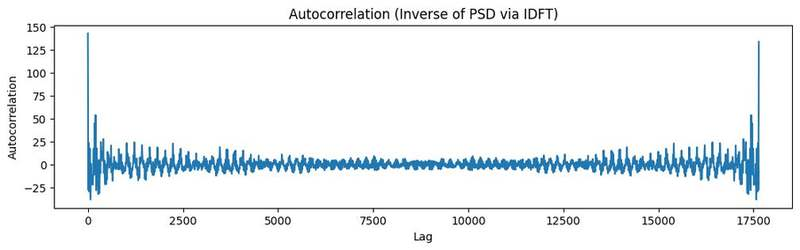

Plots for consonant 3


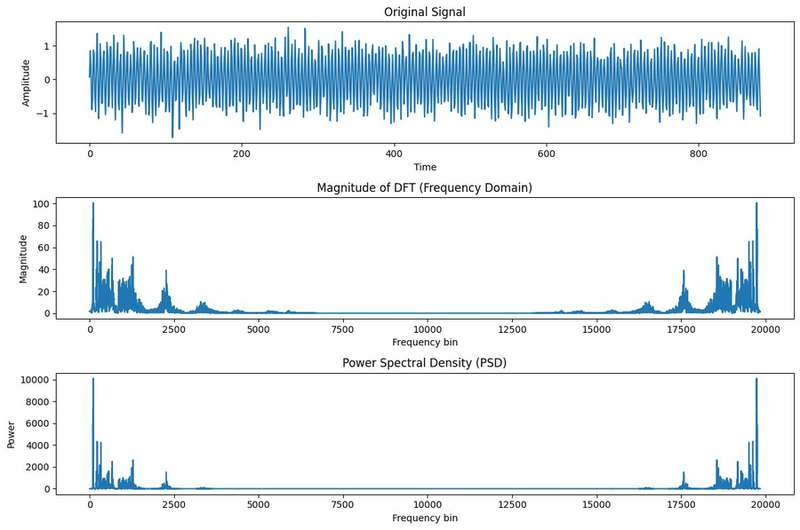

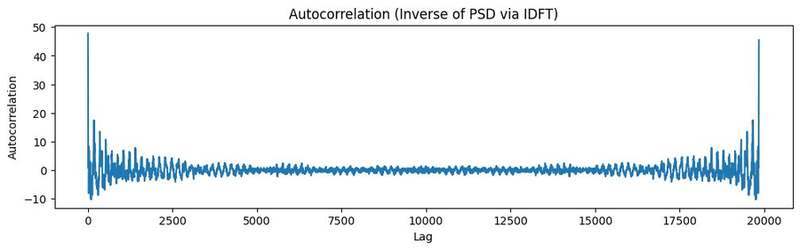

In [105]:
for c, idx in zip(consonants, [i for i in range(1,len(consonants)+1)]):
    print(f"Plots for consonant {idx}")
    fft_signal, psd, auto_corr = wiener_khinchin_autocorrelation(c)

Plots for consonant 1 (built-in)


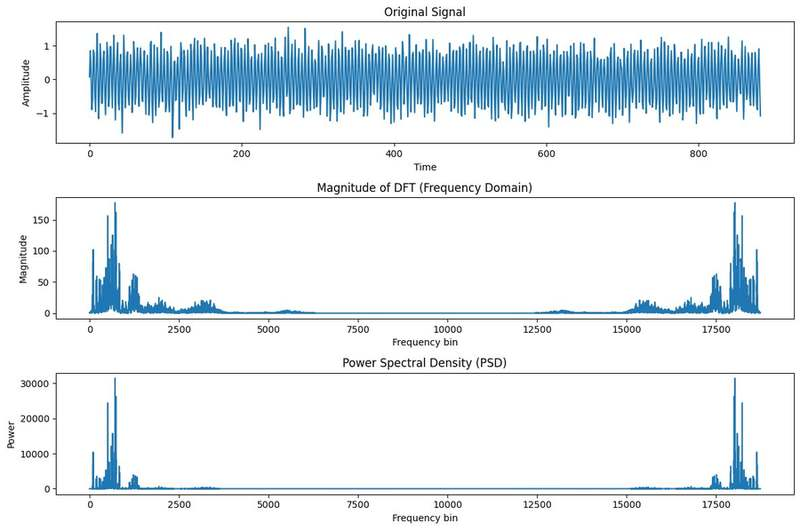

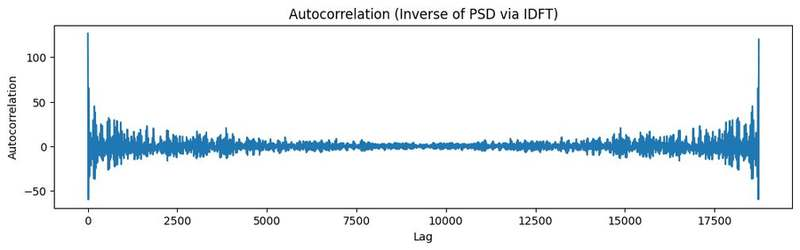

Plots for consonant 2 (built-in)


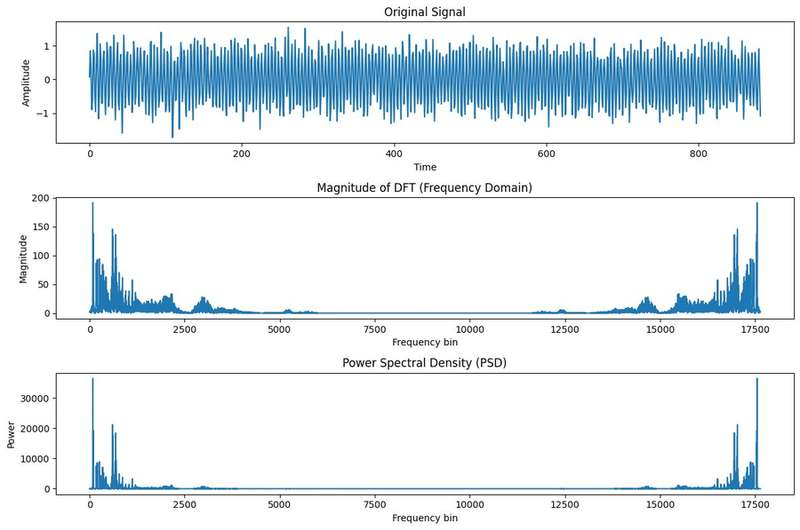

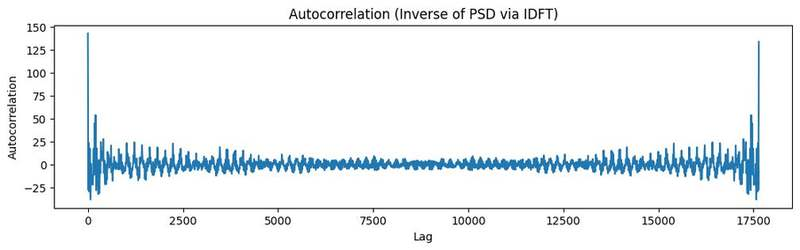

Plots for consonant 3 (built-in)


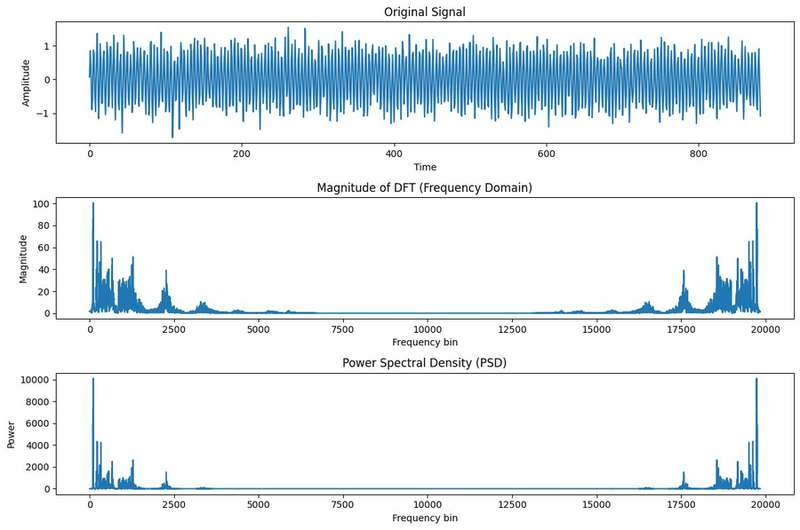

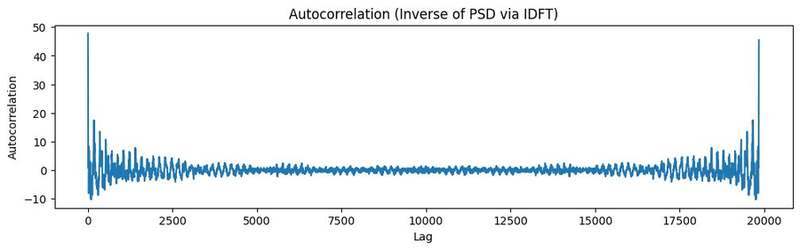

In [106]:
for c, idx in zip(consonants, [i for i in range(1,len(consonants)+1)]):
    print(f"Plots for consonant {idx} (built-in)")
    fft_signal, psd, auto_corr = wiener_khinchin_autocorrelation_builtin(c)